# Portafolio Módulo 6 Big Data
### Kamila Martínez A01711833

TABLEAU

https://public.tableau.com/views/portafolio_bigdata/Anlisisdeofertas?:language=en-GB&:sid=&:redirect=auth&showOnboarding=true&:display_count=n&:origin=viz_share_link

Existen dos dashboards, Analisis de ofertas y Modelo.

# Parte 1: Preparación del ambiente de trabajo en Colab


### Paso 0: Revisión del entorno

Primero reviso con qué recursos cuenta la máquina de Colab, porque de eso depende cómo configuro Spark más adelante.

In [107]:
import sys, os, platform, multiprocessing

print("Python:", sys.version.split()[0])
print("Sistema operativo:", platform.platform())
print("Núcleos de CPU:", multiprocessing.cpu_count())

try:
    import psutil
    print(f"Memoria RAM total: {psutil.virtual_memory().total / 1e9:.1f} GB")
except ImportError:
    pass

try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
print("Corriendo en Colab:", EN_COLAB)

Python: 3.13.18
Sistema operativo: Linux-6.6.159+-x86_64-with-glibc2.39
Núcleos de CPU: 2
Memoria RAM total: 13.6 GB
Corriendo en Colab: True


### Paso 1: Java

Reviso si ya hay una versión de Java compatible. Si no hay o es menor a la 17, instalo OpenJDK 17. Después guardo la ruta en la variable JAVA_HOME para que PySpark sepa dónde está.

In [108]:
import subprocess, re, shutil, glob

def version_java():
    if shutil.which("java") is None:
        return None
    salida = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
    m = re.search(r'version "(\d+)', salida)
    return int(m.group(1)) if m else None

v = version_java()
if v is None or v < 17:
    print("Instalando OpenJDK 17...")
    subprocess.run("apt-get update -qq && apt-get install -y -qq openjdk-17-jdk-headless > /dev/null",
                   shell=True, check=True)
    rutas = glob.glob("/usr/lib/jvm/java-17-openjdk*")
    os.environ["JAVA_HOME"] = rutas[0]
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
else:
    # Si ya hay un Java compatible se usa ese
    java_bin = os.path.realpath(shutil.which("java"))
    os.environ["JAVA_HOME"] = os.path.dirname(os.path.dirname(java_bin))

print("Versión de Java:", version_java())
print("JAVA_HOME:", os.environ["JAVA_HOME"])

Versión de Java: 21
JAVA_HOME: /usr/lib/jvm/java-21-openjdk-amd64


### Paso 2: PySpark

El paquete de PySpark ya trae Spark incluido, entonces no hace falta descargarlo por separado. También instalo kagglehub, que es la librería con la que descargo el dataset.

In [109]:
!pip install -q pyspark kagglehub

import pyspark
print("Versión de PySpark:", pyspark.__version__)

Versión de PySpark: 4.0.5


### Paso 3: SparkSession

Creo la sesión con la siguiente configuración:

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| master | local[*] | Spark corre en la máquina de Colab y usa todos los núcleos disponibles |
| spark.driver.memory | 4g | Memoria del driver, que en modo local también es el que procesa los datos |
| spark.sql.shuffle.partitions | núcleos por 4 | El valor por defecto es 200, que es demasiado para una sola máquina y genera muchas tareas pequeñas |
| spark.driver.host | 127.0.0.1 | Evita errores de red al iniciar la sesión en Colab |
| spark.ui.showConsoleProgress | false | Quita las barras de progreso para que las salidas se vean limpias |

In [110]:
from pyspark.sql import SparkSession

nucleos = multiprocessing.cpu_count()

spark = SparkSession.builder \
    .appName("Portafolio_BigData_Kamila") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", str(nucleos * 4)) \
    .config("spark.driver.host", "127.0.0.1") \
    .config("spark.ui.showConsoleProgress", "false") \
    .getOrCreate()

spark.sparkContext.setLogLevel("ERROR")
print("Sesión de Spark iniciada correctamente.")

Sesión de Spark iniciada correctamente.


### Paso 4: Verificación de la configuración

In [111]:
sc = spark.sparkContext
print("Versión de Spark:", spark.version)
print("Master:", sc.master)
print("Nombre de la app:", sc.appName)
print("Paralelismo por defecto:", sc.defaultParallelism)
print("Particiones de shuffle:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Memoria del driver:", spark.conf.get("spark.driver.memory"))

Versión de Spark: 4.0.5
Master: local[*]
Nombre de la app: Portafolio_BigData_Kamila
Paralelismo por defecto: 2
Particiones de shuffle: 8
Memoria del driver: 4g


### Paso 5: Google Drive

Conecto Google Drive para guardar ahí el dataset limpio y el modelo. Los archivos que se guardan en Colab se borran cuando se cierra la sesión, y así no tengo que repetir la limpieza ni el entrenamiento cada vez.

In [112]:
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    print("No se está en Colab, no se monta Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Paso 6: Configuración de las gráficas

Defino una sola vez el estilo y los colores que uso en todas las gráficas del notebook, naranja para Associate y azul para Mid senior. Cada gráfica va justo después del cálculo que representa, seguida de su interpretación.

In [113]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="whitegrid")
COLOR_ASSOC = "#DD8452"
COLOR_MID = "#4C72B0"
COLOR_GRIS = "#9AA0A6"
COLORES_NIVEL = {"Associate": COLOR_ASSOC, "Mid senior": COLOR_MID}

def etiquetar_barras(ax, formato="{:,.0f}", tam=9):
    for cont in ax.containers:
        ax.bar_label(cont, labels=[formato.format(v) for v in cont.datavalues], padding=3, fontsize=tam)

# Parte 2: Selección de la base de datos

Elegí el dataset 1.3M LinkedIn Jobs and Skills 2024 de Kaggle. Tiene más de 1.3 millones de ofertas de trabajo publicadas en LinkedIn en enero de 2024 y está dividido en tres archivos que se relacionan por la columna job_link.

| Archivo | Tamaño | Contenido |
|---|---|---|
| linkedin_job_postings.csv | 0.42 GB | Título, empresa, ubicación, país, ciudad, nivel y tipo de empleo de cada oferta |
| job_skills.csv | 0.67 GB | Habilidades que pide cada oferta, separadas por comas |
| job_summary.csv | 5.10 GB | Descripción completa del puesto |

El archivo job_summary.csv no lo uso porque es texto libre muy pesado y para el análisis me basta con el título y las habilidades. Lo considero Big Data porque solo con los dos archivos que sí uso ya son más de 1 GB y más de un millón de registros, y trabajar eso en una sola máquina con herramientas como pandas sería lento y usaría mucha memoria.

In [114]:
import kagglehub

path = kagglehub.dataset_download("asaniczka/1-3m-linkedin-jobs-and-skills-2024")
print("Carpeta:", path)

for archivo in sorted(os.listdir(path)):
    print(f"{archivo:35s} {os.path.getsize(os.path.join(path, archivo)) / 1e9:.2f} GB")

Using Colab cache for faster access to the '1-3m-linkedin-jobs-and-skills-2024' dataset.
Carpeta: /kaggle/input/1-3m-linkedin-jobs-and-skills-2024
job_skills.csv                      0.67 GB
job_summary.csv                     5.10 GB
linkedin_job_postings.csv           0.42 GB


Leo los dos archivos sin la opción multiLine. Con esa opción Spark no puede dividir el archivo y todo queda en una sola partición, o sea que se pierde el procesamiento en paralelo. Lo malo es que algunas ofertas tienen saltos de línea dentro de un campo y se parten en dos filas, pero esas filas las detecto y las quito en la preparación de datos.

In [115]:
opciones = {"header": True, "escape": '"'}

df_jobs_raw = spark.read.options(**opciones).csv(os.path.join(path, "linkedin_job_postings.csv"))
df_skills_raw = spark.read.options(**opciones).csv(os.path.join(path, "job_skills.csv"))

print("Particiones postings:", df_jobs_raw.rdd.getNumPartitions())
print("Particiones skills:", df_skills_raw.rdd.getNumPartitions())
print(f"Postings: {df_jobs_raw.count():,} filas, {len(df_jobs_raw.columns)} columnas")
print(f"Skills: {df_skills_raw.count():,} filas, {len(df_skills_raw.columns)} columnas")
df_jobs_raw.printSchema()
df_jobs_raw.show(5, truncate=40)

Particiones postings: 4
Particiones skills: 6
Postings: 1,348,488 filas, 14 columnas
Skills: 1,296,381 filas, 2 columnas
root
 |-- job_link: string (nullable = true)
 |-- last_processed_time: string (nullable = true)
 |-- got_summary: string (nullable = true)
 |-- got_ner: string (nullable = true)
 |-- is_being_worked: string (nullable = true)
 |-- job_title: string (nullable = true)
 |-- company: string (nullable = true)
 |-- job_location: string (nullable = true)
 |-- first_seen: string (nullable = true)
 |-- search_city: string (nullable = true)
 |-- search_country: string (nullable = true)
 |-- search_position: string (nullable = true)
 |-- job_level: string (nullable = true)
 |-- job_type: string (nullable = true)

+----------------------------------------+-----------------------------+-----------+-------+---------------+----------------------------------------+----------------------------+--------------------+----------+-----------+--------------+---------------------------------

# Parte 3: Preparación de datos

Antes de describir los datos reviso su calidad y corrijo los problemas que encuentre. El orden que seguí fue revisar filas rotas, nulos y duplicados, quitar lo que no sirve, unir las ofertas con sus habilidades, limpiar el texto, crear variables nuevas y guardar el resultado.

### 3.1 Diagnóstico de calidad

Una fila es válida si su job_link empieza con http. Si no empieza así, es un pedazo de otra oferta que se partió por un salto de línea. También cuento los links repetidos y los valores nulos o vacíos de cada columna.

In [116]:
from pyspark.sql import functions as F

def diagnostico(df, nombre):
    total = df.count()
    rotas = df.filter(~F.col("job_link").rlike("^https?://")).count()
    duplicados = total - df.select("job_link").distinct().count()
    print(f"{nombre}")
    print(f"Filas totales: {total:,}")
    print(f"Filas rotas: {rotas:,}")
    print(f"job_link duplicados: {duplicados:,}")

    # Nulos y textos vacíos por columna
    df.select([
        F.sum((F.col(c).isNull() | (F.trim(F.col(c)) == "")).cast("int")).alias(c)
        for c in df.columns
    ]).show(vertical=True)

diagnostico(df_jobs_raw, "linkedin_job_postings")
diagnostico(df_skills_raw, "job_skills")

linkedin_job_postings
Filas totales: 1,348,488
Filas rotas: 34
job_link duplicados: 25
-RECORD 0------------------
 job_link            | 0   
 last_processed_time | 0   
 got_summary         | 0   
 got_ner             | 0   
 is_being_worked     | 0   
 job_title           | 0   
 company             | 45  
 job_location        | 53  
 first_seen          | 34  
 search_city         | 68  
 search_country      | 68  
 search_position     | 68  
 job_level           | 68  
 job_type            | 68  

job_skills
Filas totales: 1,296,381
Filas rotas: 0
job_link duplicados: 0
-RECORD 0----------
 job_link   | 0    
 job_skills | 2007 



En el archivo de ofertas aparecieron 34 filas rotas, 25 links duplicados y algunos nulos en empresa y ubicación. Los 68 nulos en país, nivel y tipo de empleo coinciden con las filas rotas y los registros incompletos. En el archivo de habilidades no hay filas rotas, pero hay 2,007 ofertas con la lista de habilidades vacía.

### 3.2 Filas rotas y columnas que no aportan

Quito las filas con un link inválido. También elimino last_processed_time, got_summary, got_ner e is_being_worked, porque son columnas de control del proceso con el que se descargaron los datos y no dicen nada de la oferta de trabajo.

In [117]:
columnas_control = ["last_processed_time", "got_summary", "got_ner", "is_being_worked"]

df_jobs = df_jobs_raw.filter(F.col("job_link").rlike("^https?://")).drop(*columnas_control)
df_skills = df_skills_raw.filter(F.col("job_link").rlike("^https?://"))

print(f"Postings válidos: {df_jobs.count():,}, se quitaron {df_jobs_raw.count() - df_jobs.count():,}")
print(f"Skills válidos: {df_skills.count():,}, se quitaron {df_skills_raw.count() - df_skills.count():,}")

Postings válidos: 1,348,454, se quitaron 34
Skills válidos: 1,296,381, se quitaron 0


### 3.3 Unión de ofertas con habilidades

Uno los dos archivos con un inner join por job_link. Uso inner porque para el modelo necesito las habilidades de cada oferta, entonces las ofertas que no tienen habilidades registradas se quedan fuera.

In [118]:
df = df_jobs.join(df_skills, on="job_link", how="inner")
n_join = df.count()
print(f"Registros después del join: {n_join:,}")
print(f"Ofertas sin habilidades que se descartaron: {df_jobs.count() - n_join:,}")

Registros después del join: 1,296,381
Ofertas sin habilidades que se descartaron: 52,073


Se perdieron alrededor de 52 mil ofertas que no tenían habilidades, que es cerca del 4 % del total, así que no afecta el volumen del análisis.

### 3.4 Nulos y duplicados

Los nulos en company y job_location los lleno con Desconocido. En el notebook de Kaggle que revisé se llenaban con el nombre de una empresa y una ciudad tomadas al azar, pero eso altera los conteos por empresa y ubicación, por eso preferí dejar una categoría aparte. Las filas sin título, nivel, tipo de empleo, país o habilidades las elimino porque son las variables que uso en el modelo y en el dashboard. Por último quito los duplicados por job_link, que es el identificador de cada oferta.

In [119]:
antes = df.count()

df = df.fillna({"company": "Desconocido", "job_location": "Desconocido"}) \
       .dropna(subset=["job_title", "job_level", "job_type", "search_country", "job_skills"]) \
       .filter(F.trim(F.col("job_skills")) != "") \
       .dropDuplicates(["job_link"])

despues = df.count()
print(f"Antes: {antes:,}, después: {despues:,}, eliminadas: {antes - despues:,}")

Antes: 1,296,381, después: 1,294,343, eliminadas: 2,038


Se eliminaron 2,038 filas, apenas el 0.16 % de los registros. La mayoría son las 2,007 ofertas que tenían la lista de habilidades vacía, y el resto son filas con nulos en las columnas del modelo o links repetidos.

### 3.5 Normalización de texto

Paso los títulos a minúsculas y les quito los espacios sobrantes, para que por ejemplo Registered Nurse y registered nurse cuenten como el mismo puesto. Las habilidades vienen como un solo texto separado por comas, entonces las convierto en una lista, las paso a minúsculas, les quito espacios y elimino las vacías y las repetidas dentro de la misma oferta.

In [120]:
df = df.withColumn("job_title", F.regexp_replace(F.lower(F.trim("job_title")), r"\s+", " ")) \
       .withColumn("skills_array",
                   F.array_distinct(
                       F.filter(
                           F.transform(F.split(F.lower("job_skills"), ","), lambda s: F.trim(s)),
                           lambda s: s != ""
                       )
                   ))

df.select("job_title", "skills_array").show(5, truncate=80)

+----------------------------------------------+--------------------------------------------------------------------------------+
|                                     job_title|                                                                    skills_array|
+----------------------------------------------+--------------------------------------------------------------------------------+
|                         operations supervisor|[operations management, leadership, communication, safety regulations, custom...|
|                        software test engineer|[software testing, manual testing, automated testing, python, typescript, doc...|
|     waiter/waitress for a 4-star deluxe hotel|[customer service, waitress, waiter, food and beverage service, verbal commun...|
|warehouse supervisors - delivery by saipem uae|[safety standards, quality control, materials inspection, nonconforming mater...|
|                        selector/a de personal|[recruiting, selection, interviewing, refe

### 3.6 Variables nuevas

| Variable | Descripción | Uso |
|---|---|---|
| num_skills | Número de habilidades que pide la oferta | Estadística y modelo |
| title_words | Número de palabras del título | Estadística y modelo |
| first_seen | Fecha de publicación convertida a tipo fecha | Dashboard |
| day_of_week | Día de la semana de la publicación | Dashboard |
| label | 1 si la oferta es Associate y 0 si es Mid senior | Variable objetivo del modelo |

A Associate le asigno el 1 porque es la clase minoritaria y es la que más me interesa que el modelo detecte.

In [121]:
df = df.withColumn("num_skills", F.size("skills_array")) \
       .withColumn("title_words", F.size(F.split("job_title", " "))) \
       .withColumn("first_seen", F.to_date("first_seen")) \
       .withColumn("day_of_week", F.date_format("first_seen", "EEEE")) \
       .withColumn("label", F.when(F.col("job_level") == "Associate", 1).otherwise(0))

df = df.select("job_link", "job_title", "company", "job_location", "search_city", "search_country",
               "search_position", "job_level", "job_type", "first_seen", "day_of_week",
               "job_skills", "skills_array", "num_skills", "title_words", "label")

df.cache()
print(f"Dataset limpio: {df.count():,} filas, {len(df.columns)} columnas")
df.printSchema()

Dataset limpio: 1,294,343 filas, 16 columnas
root
 |-- job_link: string (nullable = true)
 |-- job_title: string (nullable = true)
 |-- company: string (nullable = false)
 |-- job_location: string (nullable = false)
 |-- search_city: string (nullable = true)
 |-- search_country: string (nullable = true)
 |-- search_position: string (nullable = true)
 |-- job_level: string (nullable = true)
 |-- job_type: string (nullable = true)
 |-- first_seen: date (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- job_skills: string (nullable = true)
 |-- skills_array: array (nullable = true)
 |    |-- element: string (containsNull = false)
 |-- num_skills: integer (nullable = true)
 |-- title_words: integer (nullable = true)
 |-- label: integer (nullable = false)



### 3.7 Guardado del dataset limpio

Guardo el resultado en formato Parquet. Es un formato por columnas y comprimido que Spark lee mucho más rápido que un CSV, y además conserva los tipos de datos, incluida la lista de habilidades. Si Drive está conectado lo guardo ahí.

In [122]:
carpeta_salida = "/content/drive/MyDrive/portafolio_bigdata" if os.path.exists("/content/drive/MyDrive") \
                 else "/content/portafolio_bigdata"
ruta_parquet = os.path.join(carpeta_salida, "linkedin_jobs_limpio.parquet")

df.write.mode("overwrite").parquet(ruta_parquet)
print("Guardado en:", ruta_parquet)
print("Registros leídos de vuelta:", spark.read.parquet(ruta_parquet).count())

Guardado en: /content/drive/MyDrive/portafolio_bigdata/linkedin_jobs_limpio.parquet
Registros leídos de vuelta: 1294343


Después de toda la limpieza quedaron 1,294,343 ofertas con 16 columnas.

### 3.8 Resumen del proceso de limpieza

Junto en una gráfica cuántos registros quedaron después de cada paso y cuántos se quitaron en cada uno. Los conteos los calcula Spark sobre los DataFrames de cada etapa.

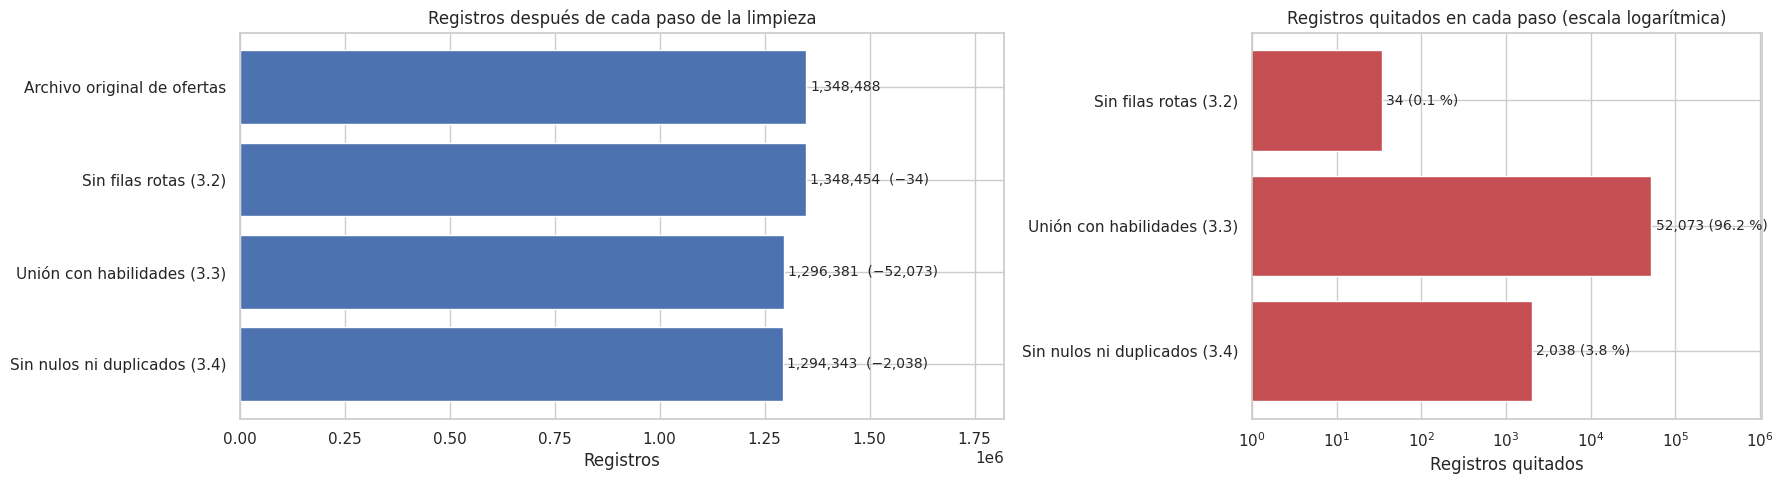

En total se quitaron 54,145 registros, el 4.02 % del archivo original


In [123]:
etapas = pd.DataFrame({
    "etapa": ["Archivo original de ofertas", "Sin filas rotas (3.2)", "Unión con habilidades (3.3)", "Sin nulos ni duplicados (3.4)"],
    "registros": [df_jobs_raw.count(), df_jobs.count(), n_join, despues],
})
etapas["quitados"] = (etapas["registros"].shift(1) - etapas["registros"]).fillna(0).astype(int)
total_quitados = etapas["registros"].iloc[0] - etapas["registros"].iloc[-1]

fig, ejes = plt.subplots(1, 2, figsize=(18, 5), gridspec_kw={"width_ratios": [1.5, 1]})

ejes[0].barh(etapas["etapa"], etapas["registros"], color=COLOR_MID)
ejes[0].bar_label(ejes[0].containers[0], padding=3, fontsize=10,
                  labels=[f"{r:,}" + (f"  (−{q:,})" if q else "") for r, q in zip(etapas["registros"], etapas["quitados"])])
ejes[0].invert_yaxis()
ejes[0].set_xlim(0, etapas["registros"].max() * 1.35)
ejes[0].set_title("Registros después de cada paso de la limpieza")
ejes[0].set_xlabel("Registros")

quitados = etapas.iloc[1:]
ejes[1].barh(quitados["etapa"], quitados["quitados"], color="#C44E52")
ejes[1].bar_label(ejes[1].containers[0], padding=3, fontsize=10,
                  labels=[f"{q:,} ({q / total_quitados * 100:.1f} %)" for q in quitados["quitados"]])
ejes[1].set_xscale("log")
ejes[1].set_xlim(1, quitados["quitados"].max() * 20)
ejes[1].invert_yaxis()
ejes[1].set_title("Registros quitados en cada paso (escala logarítmica)")
ejes[1].set_xlabel("Registros quitados")

plt.tight_layout()
plt.show()
print(f"En total se quitaron {total_quitados:,} registros, el {total_quitados / etapas['registros'].iloc[0] * 100:.2f} % del archivo original")

En la gráfica de la izquierda las cuatro barras miden casi lo mismo, que es justo lo que quería comprobar. De 1,348,488 ofertas en el archivo original quedaron 1,294,343, así que la limpieza quitó 54,145 registros, apenas el 4.0 %, y el dataset sigue siendo de más de un millón de ofertas. La gráfica de la derecha muestra de dónde salió esa pérdida. Uso escala logarítmica porque las cantidades son muy distintas. Casi todo, 52,073 registros que son el 96.2 %, se quitó en la unión con habilidades, por las ofertas que no tenían habilidades registradas. Las 34 filas rotas por saltos de línea y los 2,038 registros con nulos o duplicados son una parte muy pequeña. Con esto confirmo que leer los archivos sin multiLine, para mantener el procesamiento en paralelo, no costó casi nada en datos perdidos.

# Parte 4: Estadística descriptiva

En esta parte describo el dataset limpio. Todos los cálculos los hago en Spark, y solo cuando voy a graficar paso a pandas las tablas ya resumidas, nunca el dataset completo.

### 4.1 Dimensiones y valores únicos

In [124]:
total = df.count()
print(f"Registros: {total:,}")
print(f"Columnas: {len(df.columns)}")

columnas_cat = ["job_title", "company", "job_location", "search_city", "search_country",
                "search_position", "job_level", "job_type", "first_seen"]

df.select([F.countDistinct(c).alias(c) for c in columnas_cat]).show(vertical=True)

rango = df.agg(F.min("first_seen").alias("primera"), F.max("first_seen").alias("ultima")).first()
print(f"Periodo de publicación: {rango['primera']} a {rango['ultima']}")

Registros: 1,294,343
Columnas: 16
-RECORD 0-----------------
 job_title       | 558971 
 company         | 88933  
 job_location    | 28777  
 search_city     | 1018   
 search_country  | 4      
 search_position | 1922   
 job_level       | 2      
 job_type        | 3      
 first_seen      | 6      

Periodo de publicación: 2024-01-12 a 2024-01-17


Hay 558,971 títulos distintos, 88,933 empresas y 28,777 ubicaciones, o sea que casi cada oferta tiene un título diferente. Esto pasa porque muchas empresas agregan datos al título, como la ciudad o el turno, y por eso tiene sentido trabajar el título como texto y no como una categoría. Todas las ofertas son del 12 al 17 de enero de 2024 y vienen solo de cuatro países.

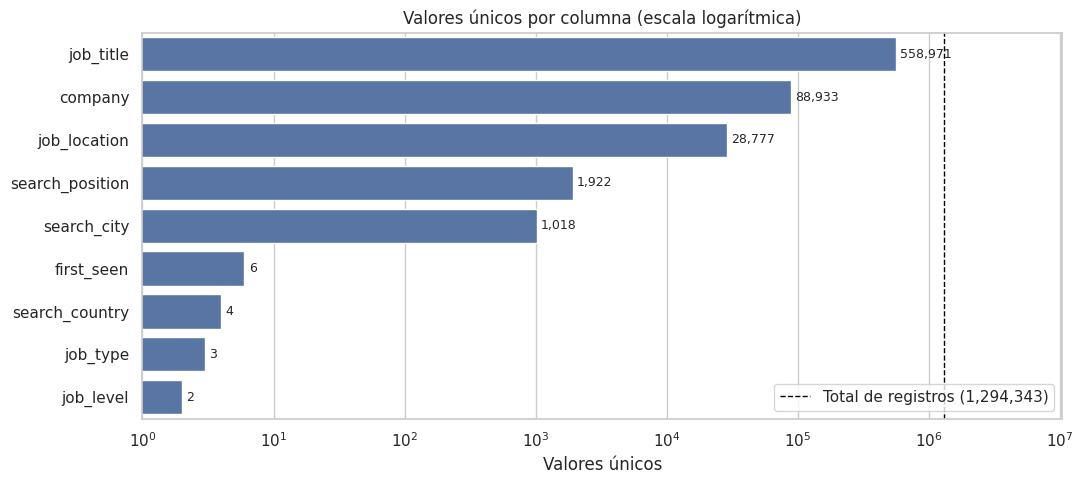

In [125]:
unicos = df.select([F.countDistinct(c).alias(c) for c in columnas_cat]).first().asDict()
pd_unicos = pd.DataFrame(list(unicos.items()), columns=["columna", "valores_unicos"]) \
              .sort_values("valores_unicos", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=pd_unicos, y="columna", x="valores_unicos", color=COLOR_MID, ax=ax)
ax.set_xscale("log")
ax.set_xlim(1, total * 8)
ax.axvline(total, color="black", linestyle="--", linewidth=1, label=f"Total de registros ({total:,})")
etiquetar_barras(ax)
ax.set_title("Valores únicos por columna (escala logarítmica)")
ax.set_xlabel("Valores únicos")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Uso escala logarítmica porque los valores van de 2 a casi 560 mil y en escala normal las columnas con pocos valores no se alcanzarían a ver. La línea punteada marca el total de registros. La barra de job_title llega muy cerca de esa línea, con 558,971 títulos distintos para 1,294,343 ofertas, y company y job_location también tienen decenas de miles de valores. En cambio job_level, job_type, search_country y first_seen tienen menos de 10 valores cada una. La gráfica deja ver dos grupos de columnas, las de pocos valores se pueden usar como categorías con one hot encoding y las de muchos valores, como el título, hay que tratarlas como texto.

### 4.2 Variables numéricas

Con summary obtengo el conteo, la media, la desviación estándar, el mínimo, los cuartiles y el máximo. También calculo la asimetría y la curtosis para ver la forma de la distribución.

In [126]:
df.select("num_skills", "title_words").summary(
    "count", "mean", "stddev", "min", "25%", "50%", "75%", "max"
).show()

df.select(
    F.skewness("num_skills").alias("skew_num_skills"),
    F.kurtosis("num_skills").alias("kurt_num_skills"),
    F.skewness("title_words").alias("skew_title_words"),
    F.kurtosis("title_words").alias("kurt_title_words"),
).show()

+-------+------------------+-----------------+
|summary|        num_skills|      title_words|
+-------+------------------+-----------------+
|  count|           1294343|          1294343|
|   mean|20.689995619399184|4.756492676207157|
| stddev|11.365288542759235|2.851316896857736|
|    min|                 1|                1|
|    25%|                13|                3|
|    50%|                19|                4|
|    75%|                25|                6|
|    max|               276|               37|
+-------+------------------+-----------------+

+------------------+----------------+------------------+-----------------+
|   skew_num_skills| kurt_num_skills|  skew_title_words| kurt_title_words|
+------------------+----------------+------------------+-----------------+
|2.3951156600996883|15.2341952116955|1.4403707641927437|2.825639606860836|
+------------------+----------------+------------------+-----------------+



En promedio cada oferta pide 20.7 habilidades con una mediana de 19, pero hay ofertas que llegan a pedir 276. La asimetría es de 2.4 y la curtosis de 15.2, lo que indica que la mayoría de las ofertas pide entre 13 y 25 habilidades y unas pocas piden muchísimas más. Los títulos tienen en promedio 4.8 palabras y la mitad tiene 4 o menos.

Comparo las mismas variables por nivel de puesto:

In [127]:
df.groupBy("job_level").agg(
    F.count("*").alias("ofertas"),
    F.round(F.mean("num_skills"), 2).alias("media_skills"),
    F.round(F.stddev("num_skills"), 2).alias("desv_skills"),
    F.percentile_approx("num_skills", 0.5).alias("mediana_skills"),
    F.round(F.mean("title_words"), 2).alias("media_palabras_titulo"),
).orderBy("job_level").show()

+----------+-------+------------+-----------+--------------+---------------------+
| job_level|ofertas|media_skills|desv_skills|mediana_skills|media_palabras_titulo|
+----------+-------+------------+-----------+--------------+---------------------+
| Associate| 140919|       20.12|       11.0|            18|                 4.69|
|Mid senior|1153424|       20.76|      11.41|            19|                 4.76|
+----------+-------+------------+-----------+--------------+---------------------+



Esperaba que las ofertas Mid senior pidieran bastantes más habilidades, pero la diferencia es mínima, 20.1 contra 20.8 en promedio, y el largo del título es casi igual. Esto quiere decir que estas dos variables por sí solas no van a ayudar mucho a separar los niveles en el modelo.

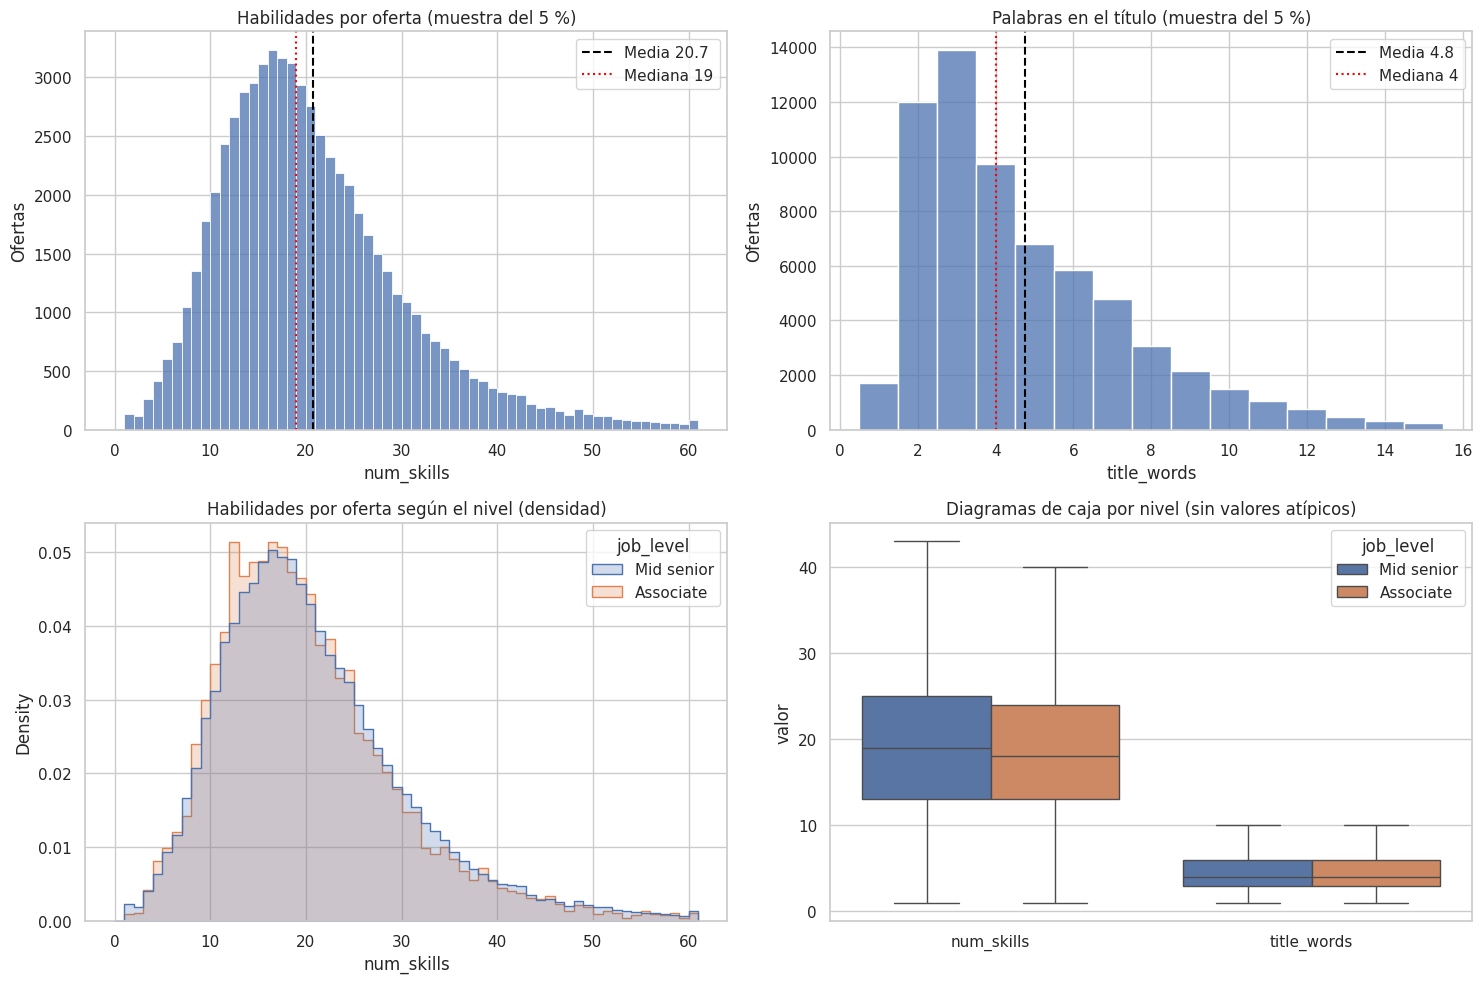

In [128]:
# Muestra aleatoria del 5 % para los histogramas y diagramas de caja
pd_muestra = df.select("num_skills", "title_words", "job_level").sample(fraction=0.05, seed=42).toPandas()
lim_skills = pd_muestra["num_skills"].quantile(0.99)

fig, ejes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col, titulo, rango in [(ejes[0, 0], "num_skills", "Habilidades por oferta", (0, lim_skills)),
                                (ejes[0, 1], "title_words", "Palabras en el título", (0.5, 15.5))]:
    sns.histplot(pd_muestra[col], binwidth=1, binrange=rango, color=COLOR_MID, ax=ax)
    ax.axvline(pd_muestra[col].mean(), color="black", linestyle="--", label=f"Media {pd_muestra[col].mean():.1f}")
    ax.axvline(pd_muestra[col].median(), color="red", linestyle=":", label=f"Mediana {pd_muestra[col].median():.0f}")
    ax.set_title(f"{titulo} (muestra del 5 %)")
    ax.set_xlabel(col)
    ax.set_ylabel("Ofertas")
    ax.legend()

sns.histplot(data=pd_muestra, x="num_skills", hue="job_level", palette=COLORES_NIVEL, binwidth=1,
             binrange=(0, lim_skills), stat="density", common_norm=False, element="step", ax=ejes[1, 0])
ejes[1, 0].set_title("Habilidades por oferta según el nivel (densidad)")

pd_largo = pd_muestra.melt(id_vars="job_level", value_vars=["num_skills", "title_words"],
                           var_name="variable", value_name="valor")
sns.boxplot(data=pd_largo, x="variable", y="valor", hue="job_level", palette=COLORES_NIVEL,
            showfliers=False, ax=ejes[1, 1])
ejes[1, 1].set_title("Diagramas de caja por nivel (sin valores atípicos)")
ejes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()

En la primera gráfica se ve la asimetría que calculé, la mayoría de las ofertas pide entre 13 y 25 habilidades y la cola se estira hacia la derecha, por eso la media de 20.7 queda a la derecha de la mediana de 19. Corté el eje en el percentil 99 porque las pocas ofertas que piden hasta 276 habilidades aplastarían el resto de la gráfica. El número de palabras del título también tiene una cola a la derecha pero más corta, y la mitad de los títulos tiene entre 3 y 6 palabras.

En la fila de abajo comparo por nivel. Las dos curvas de densidad de habilidades casi se enciman y en los diagramas de caja las medianas son de 18 y 19 habilidades, con cajas prácticamente del mismo tamaño. Con el título pasa lo mismo. Esto confirma de forma visual lo que vi en la tabla, ni el número de habilidades ni el largo del título separan a Associate de Mid senior.

### 4.3 Distribución de las variables categóricas

In [129]:
def frecuencias(columna, n=10):
    print(f"\n{columna}")
    df.groupBy(columna).count() \
      .withColumn("porcentaje", F.round(F.col("count") / total * 100, 2)) \
      .orderBy(F.col("count").desc()) \
      .show(n, truncate=False)

for c in ["job_level", "job_type", "search_country", "first_seen", "day_of_week"]:
    frecuencias(c)


job_level
+----------+-------+----------+
|job_level |count  |porcentaje|
+----------+-------+----------+
|Mid senior|1153424|89.11     |
|Associate |140919 |10.89     |
+----------+-------+----------+


job_type
+--------+-------+----------+
|job_type|count  |porcentaje|
+--------+-------+----------+
|Onsite  |1283529|99.16     |
|Hybrid  |6560   |0.51      |
|Remote  |4254   |0.33      |
+--------+-------+----------+


search_country
+--------------+-------+----------+
|search_country|count  |porcentaje|
+--------------+-------+----------+
|United States |1103677|85.27     |
|United Kingdom|108352 |8.37      |
|Canada        |53837  |4.16      |
|Australia     |28477  |2.2       |
+--------------+-------+----------+


first_seen
+----------+------+----------+
|first_seen|count |porcentaje|
+----------+------+----------+
|2024-01-14|458609|35.43     |
|2024-01-13|403327|31.16     |
|2024-01-12|205896|15.91     |
|2024-01-16|123579|9.55      |
|2024-01-15|79249 |6.12      |
|2024-01-1

El 89.11 % de las ofertas son Mid senior y solo el 10.89 % son Associate, entonces las clases están muy desbalanceadas. El tipo de empleo casi no varía, el 99.16 % es presencial, por eso no lo uso como variable objetivo. Estados Unidos concentra el 85.27 % de las ofertas, seguido de Reino Unido, Canadá y Australia. En las fechas, el 35 % de las ofertas cae en domingo y el 31 % en sábado, pero eso tiene más que ver con los días en que se descargaron los datos que con un patrón real de publicación, así que no saco conclusiones de esa variable.

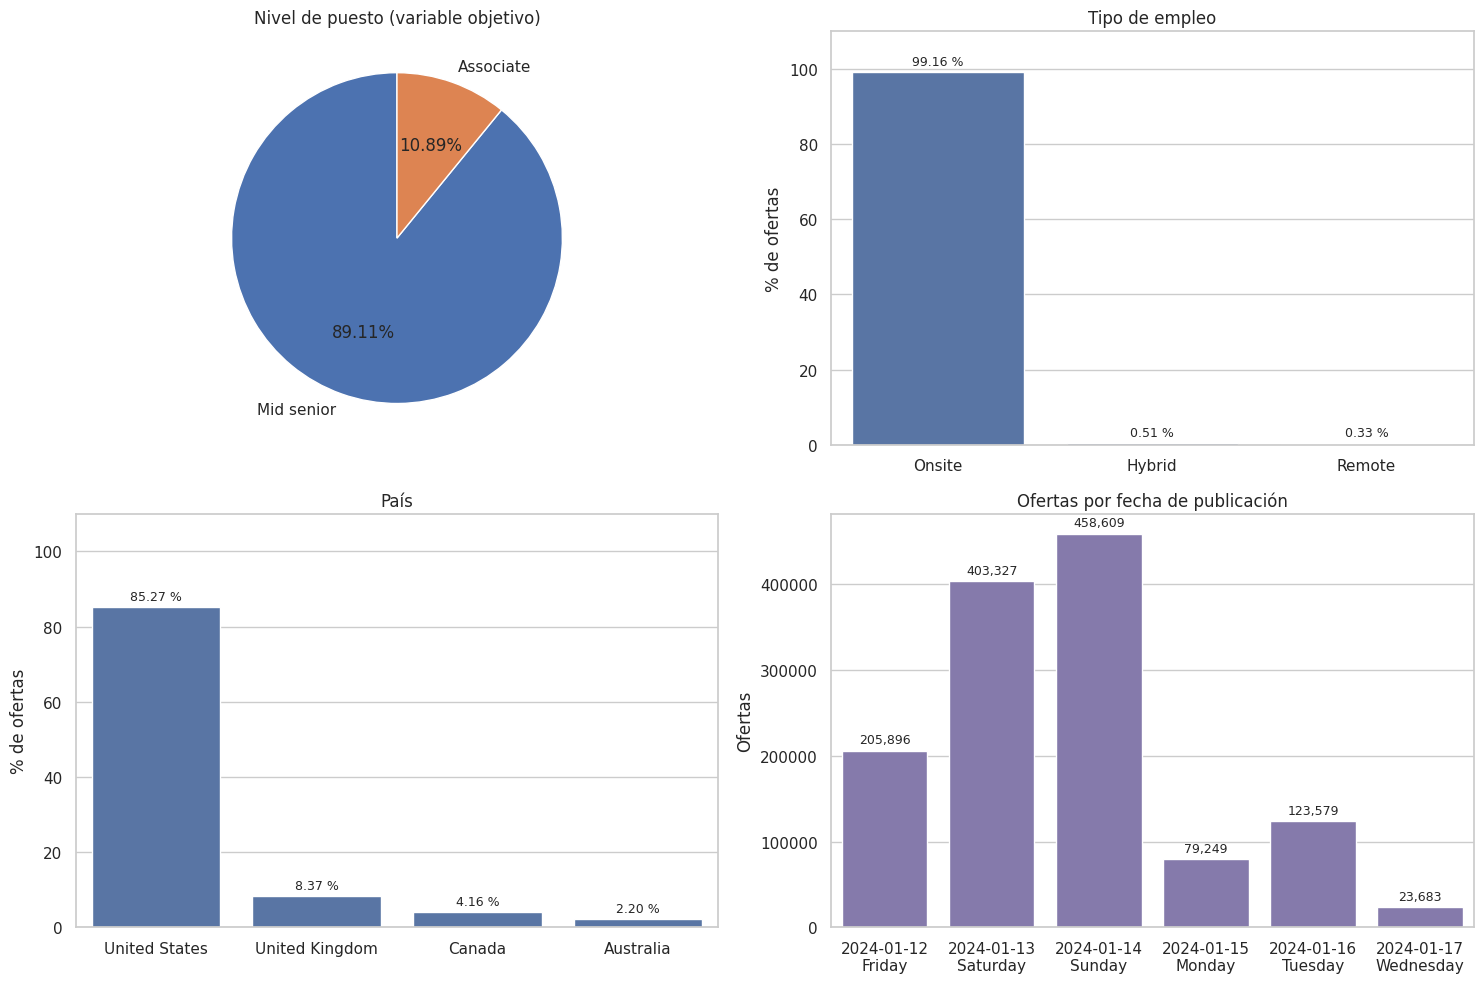

In [130]:
def conteo(col):
    return df.groupBy(col).count() \
             .withColumn("pct", F.col("count") / total * 100) \
             .orderBy(F.col("count").desc()).toPandas()

fig, ejes = plt.subplots(2, 2, figsize=(15, 10))

pd_nivel = conteo("job_level")
ejes[0, 0].pie(pd_nivel["count"], labels=pd_nivel["job_level"], autopct="%1.2f%%", startangle=90,
               colors=[COLORES_NIVEL[n] for n in pd_nivel["job_level"]], wedgeprops={"edgecolor": "white"})
ejes[0, 0].set_title("Nivel de puesto (variable objetivo)")

for ax, col, titulo in [(ejes[0, 1], "job_type", "Tipo de empleo"), (ejes[1, 0], "search_country", "País")]:
    pd_c = conteo(col)
    sns.barplot(data=pd_c, x=col, y="pct", color=COLOR_MID, ax=ax)
    etiquetar_barras(ax, "{:.2f} %")
    ax.set_ylim(0, 110)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("% de ofertas")

pd_fecha = df.groupBy("first_seen", "day_of_week").count().orderBy("first_seen").toPandas()
pd_fecha["etiqueta"] = pd_fecha["first_seen"].astype(str) + "\n" + pd_fecha["day_of_week"]
sns.barplot(data=pd_fecha, x="etiqueta", y="count", color="#8172B3", ax=ejes[1, 1])
etiquetar_barras(ejes[1, 1])
ejes[1, 1].set_title("Ofertas por fecha de publicación")
ejes[1, 1].set_xlabel("")
ejes[1, 1].set_ylabel("Ofertas")

plt.tight_layout()
plt.show()

La gráfica de pastel deja ver lo desbalanceada que está la variable objetivo, solo una de cada nueve ofertas es Associate. En el tipo de empleo la barra de presencial llega al 99.16 % y las de híbrido y remoto casi no se ven, con 0.51 % y 0.33 %, por eso esta variable no sirve como objetivo y aporta poca información para la mayoría de las ofertas. En países, Estados Unidos tiene el 85.27 % y los otros tres países juntos no llegan al 15 %. En las fechas, el sábado 13 y el domingo 14 de enero juntan dos de cada tres ofertas, y el miércoles 17 solo tiene el 1.83 %, lo que parece más un efecto de cuándo se descargaron los datos que un patrón real de publicación.

### 4.4 Puestos, empresas y ubicaciones más frecuentes

In [131]:
for c in ["job_title", "company", "job_location", "search_city"]:
    frecuencias(c, n=10)


job_title
+-------------------------------+-----+----------+
|job_title                      |count|porcentaje|
+-------------------------------+-----+----------+
|customer service representative|9390 |0.73      |
|lead sales associate-ft        |7315 |0.57      |
|store manager                  |5688 |0.44      |
|shift manager                  |5531 |0.43      |
|first year tax professional    |5351 |0.41      |
|assistant manager              |5252 |0.41      |
|lead sales associate-pt        |4911 |0.38      |
|registered nurse               |4279 |0.33      |
|host                           |2914 |0.23      |
|hourly supervisor & training   |2883 |0.22      |
+-------------------------------+-----+----------+
only showing top 10 rows

company
+----------------------+-----+----------+
|company               |count|porcentaje|
+----------------------+-----+----------+
|Health eCareers       |40013|3.09      |
|Jobs for Humanity     |25627|1.98      |
|TravelNurseSource     |15997|1

Los puestos con más ofertas son de servicio al cliente, ventas y gerencia de tienda, y ninguno pasa del 1 % del total, lo que confirma que los títulos están muy repartidos. Las empresas con más publicaciones son agencias de reclutamiento y bolsas de trabajo como Health eCareers y Jobs for Humanity, más que empleadores directos. En ubicaciones dominan ciudades grandes como Nueva York, Londres, Houston y Chicago.

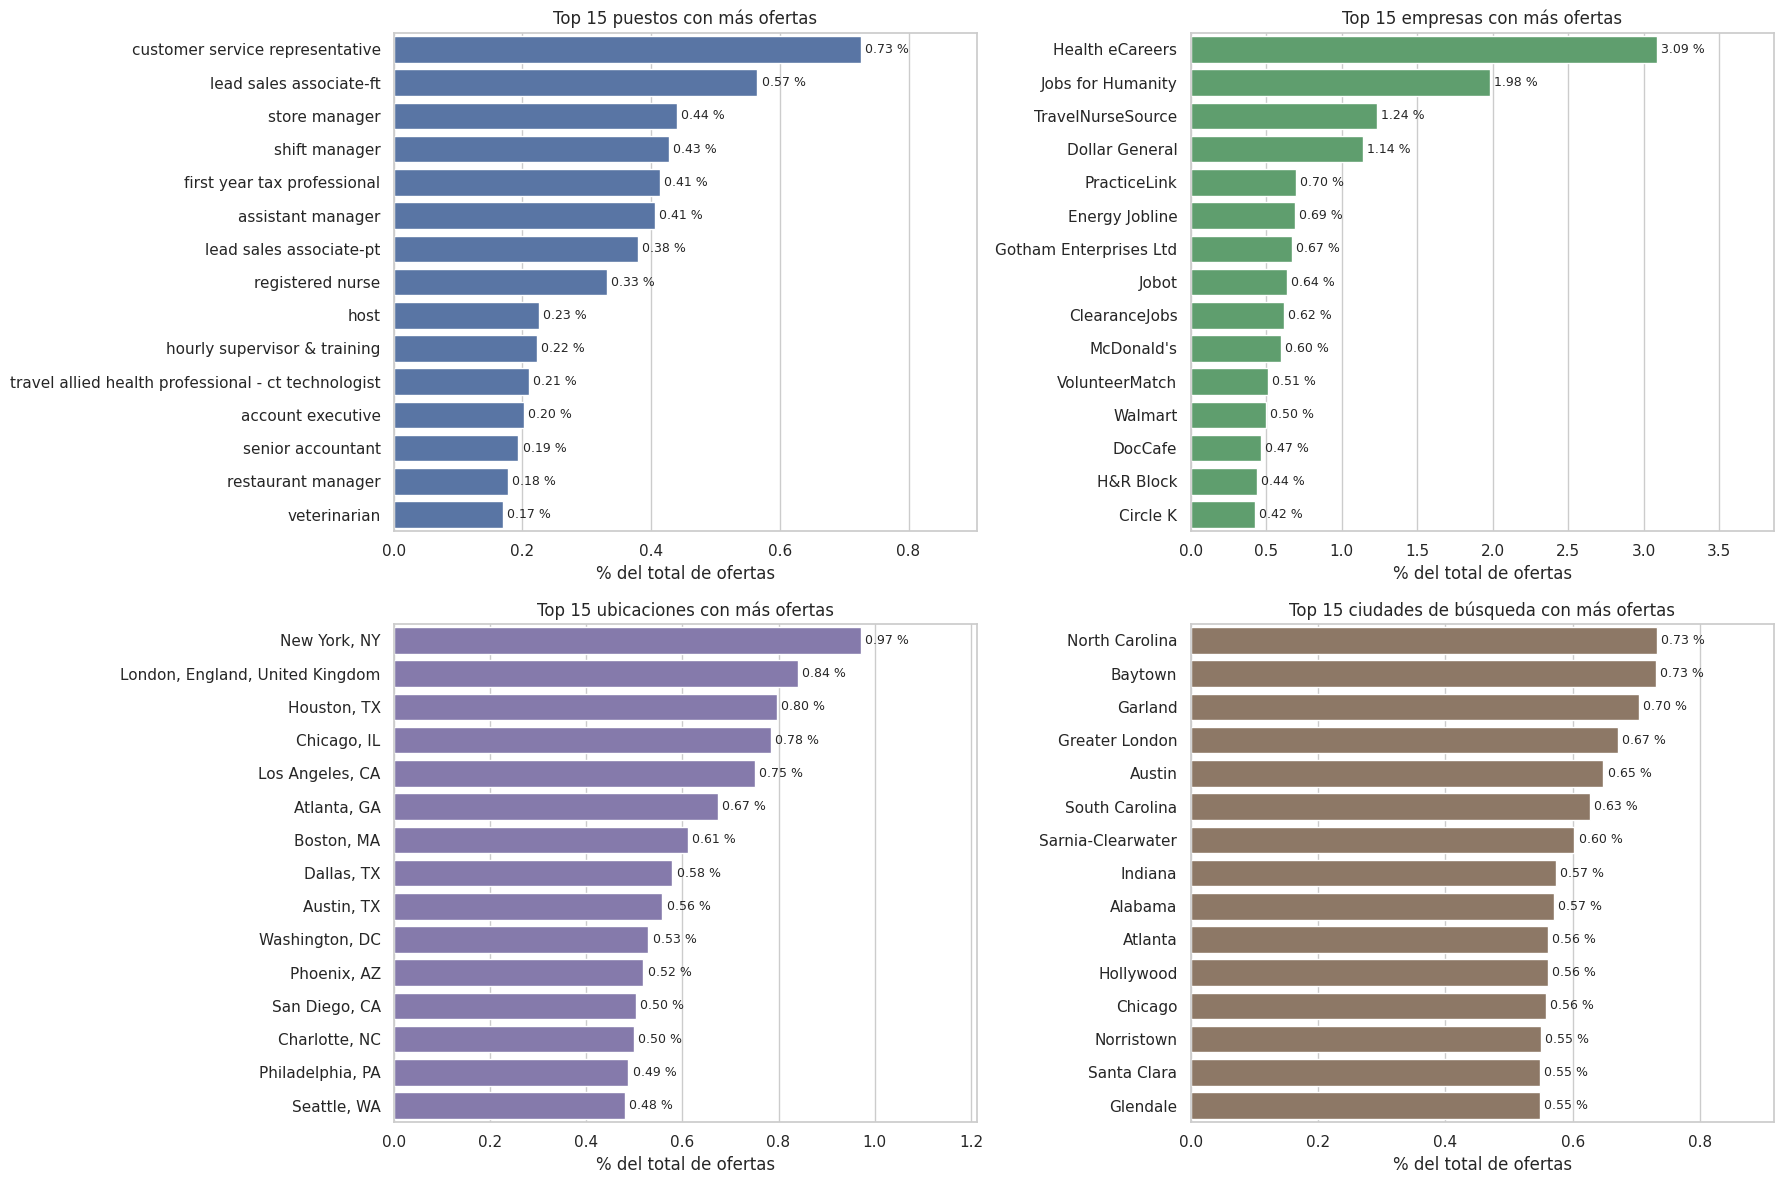

In [132]:
fig, ejes = plt.subplots(2, 2, figsize=(18, 12))
config = [("job_title", "puestos", COLOR_MID), ("company", "empresas", "#55A868"),
          ("job_location", "ubicaciones", "#8172B3"), ("search_city", "ciudades de búsqueda", "#937860")]

for ax, (col, nombre, color) in zip(ejes.flat, config):
    pd_top = df.groupBy(col).count().orderBy(F.col("count").desc()).limit(15).toPandas()
    pd_top["pct"] = pd_top["count"] / total * 100
    sns.barplot(data=pd_top, y=col, x="pct", color=color, ax=ax)
    etiquetar_barras(ax, "{:.2f} %")
    ax.set_xlim(0, pd_top["pct"].max() * 1.25)
    ax.set_title(f"Top 15 {nombre} con más ofertas")
    ax.set_xlabel("% del total de ofertas")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

Grafiqué el porcentaje sobre el total en lugar del conteo para que se vea qué tan poco representa cada valor. El puesto más común, customer service representative, apenas llega al 0.73 %, y en ubicaciones Nueva York, que es la primera, tiene el 0.97 %. La única barra que destaca es Health eCareers con el 3.09 % de las ofertas, seguida de Jobs for Humanity con 1.98 % y TravelNurseSource con 1.24 %, que son bolsas de trabajo y no empleadores directos. Que ninguna barra pase del 4 % confirma que estas columnas tienen una cola muy larga de valores con pocas ofertas cada uno.

### 4.5 Habilidades

Uso explode para que cada habilidad de la lista quede en su propia fila. Esto genera más de 26 millones de filas, así que es una buena parte para aprovechar el procesamiento distribuido de Spark.

In [133]:
df_skill_rows = df.select("job_level", F.explode("skills_array").alias("skill"))

print(f"Total de menciones de habilidades: {df_skill_rows.count():,}")
print(f"Habilidades distintas: {df_skill_rows.select('skill').distinct().count():,}")

top_skills = df_skill_rows.groupBy("skill").count() \
    .withColumn("pct_ofertas", F.round(F.col("count") / total * 100, 2)) \
    .orderBy(F.col("count").desc())
top_skills.show(20, truncate=False)

Total de menciones de habilidades: 26,779,951
Habilidades distintas: 2,773,165
+----------------------+------+-----------+
|skill                 |count |pct_ofertas|
+----------------------+------+-----------+
|communication         |365919|28.27      |
|customer service      |276454|21.36      |
|teamwork              |226010|17.46      |
|communication skills  |195058|15.07      |
|leadership            |183679|14.19      |
|problem solving       |146016|11.28      |
|time management       |142006|10.97      |
|attention to detail   |132662|10.25      |
|problemsolving        |127038|9.81       |
|project management    |120046|9.27       |
|interpersonal skills  |99872 |7.72       |
|patient care          |99397 |7.68       |
|sales                 |92632 |7.16       |
|nursing               |87776 |6.78       |
|collaboration         |86224 |6.66       |
|training              |82674 |6.39       |
|data analysis         |80849 |6.25       |
|organizational skills |74948 |5.79      

Hay 26.8 millones de menciones y 2.77 millones de habilidades distintas. Las más pedidas son habilidades blandas, comunicación aparece en el 28 % de las ofertas, servicio al cliente en el 21 % y trabajo en equipo en el 17 %. También noté que una misma habilidad aparece escrita de varias formas, como problem solving y problemsolving, o communication y communication skills, y por eso el número de habilidades distintas es tan alto.

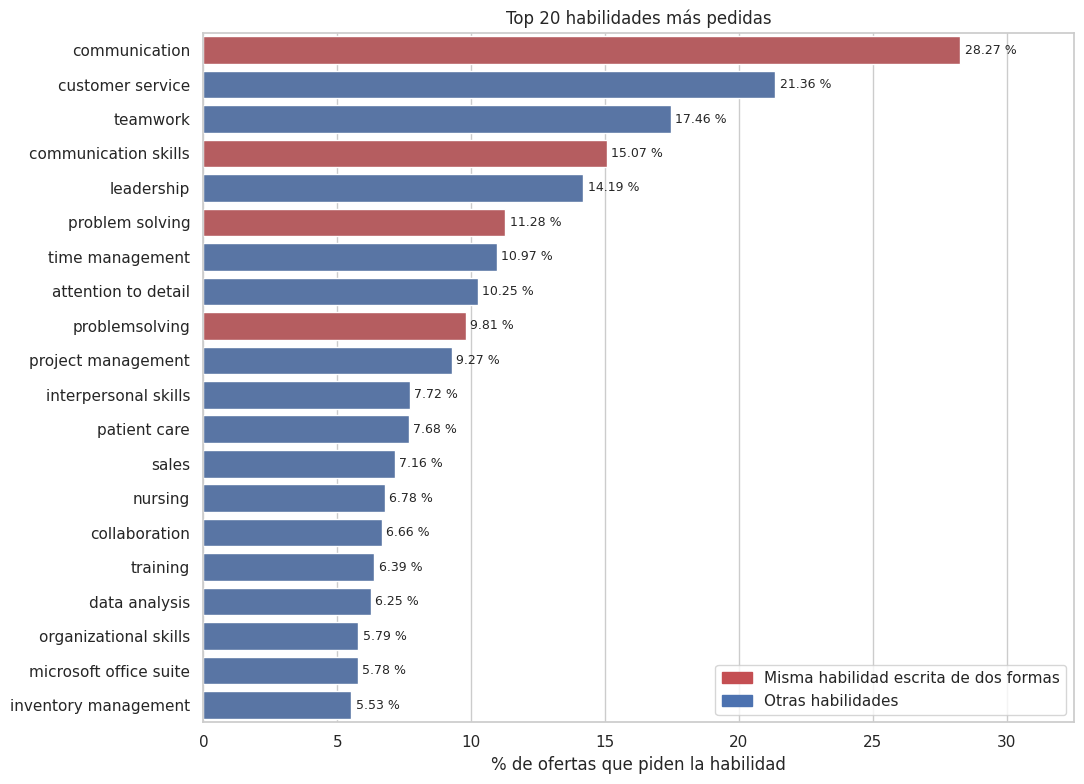

In [134]:
pd_top_sk = top_skills.limit(20).toPandas()
variantes = {"communication", "communication skills", "problem solving", "problemsolving"}
paleta_sk = {s: ("#C44E52" if s in variantes else COLOR_MID) for s in pd_top_sk["skill"]}

fig, ax = plt.subplots(figsize=(11, 8))
sns.barplot(data=pd_top_sk, y="skill", x="pct_ofertas", hue="skill", palette=paleta_sk, legend=False, ax=ax)
etiquetar_barras(ax, "{:.2f} %")
ax.set_xlim(0, pd_top_sk["pct_ofertas"].max() * 1.15)
ax.set_title("Top 20 habilidades más pedidas")
ax.set_xlabel("% de ofertas que piden la habilidad")
ax.set_ylabel("")
ax.legend(handles=[Patch(color="#C44E52", label="Misma habilidad escrita de dos formas"),
                   Patch(color=COLOR_MID, label="Otras habilidades")], loc="lower right")
plt.tight_layout()
plt.show()

Casi todo el top 20 son habilidades blandas. Communication aparece en el 28.27 % de las ofertas, customer service en el 21.36 % y teamwork en el 17.46 %, y entre las habilidades más técnicas aparecen project management con 9.27 %, patient care con 7.68 % y nursing con 6.78 %, que vienen de las muchas ofertas del área de salud. En rojo marqué los casos donde una misma habilidad aparece escrita de dos formas, communication y communication skills, y problem solving y problemsolving. Si se unificaran, problem solving subiría varios lugares, aunque no se pueden sumar directo porque algunas ofertas traen las dos versiones. Esto explica por qué hay 2.77 millones de habilidades distintas y es una de las limitaciones que menciono al final.

Habilidades más pedidas por nivel de puesto:

In [135]:
from pyspark.sql.window import Window

ventana = Window.partitionBy("job_level").orderBy(F.col("count").desc())

df_skill_rows.groupBy("job_level", "skill").count() \
    .withColumn("rank", F.row_number().over(ventana)) \
    .filter(F.col("rank") <= 10) \
    .orderBy("job_level", "rank") \
    .show(20, truncate=False)

+----------+--------------------+------+----+
|job_level |skill               |count |rank|
+----------+--------------------+------+----+
|Associate |communication       |39168 |1   |
|Associate |customer service    |30735 |2   |
|Associate |teamwork            |28223 |3   |
|Associate |communication skills|21348 |4   |
|Associate |time management     |18093 |5   |
|Associate |attention to detail |17095 |6   |
|Associate |problem solving     |15567 |7   |
|Associate |problemsolving      |13906 |8   |
|Associate |sales               |13416 |9   |
|Associate |leadership          |13034 |10  |
|Mid senior|communication       |326751|1   |
|Mid senior|customer service    |245719|2   |
|Mid senior|teamwork            |197787|3   |
|Mid senior|communication skills|173710|4   |
|Mid senior|leadership          |170645|5   |
|Mid senior|problem solving     |130449|6   |
|Mid senior|time management     |123913|7   |
|Mid senior|attention to detail |115567|8   |
|Mid senior|problemsolving      |1

Las primeras habilidades son casi las mismas en los dos niveles. La diferencia está en que en Mid senior aparecen liderazgo y gestión de proyectos más arriba, y en Associate aparecen ventas y atención al detalle. Esto me dice que las habilidades más comunes no distinguen el nivel y que el modelo tiene que apoyarse en habilidades más específicas.

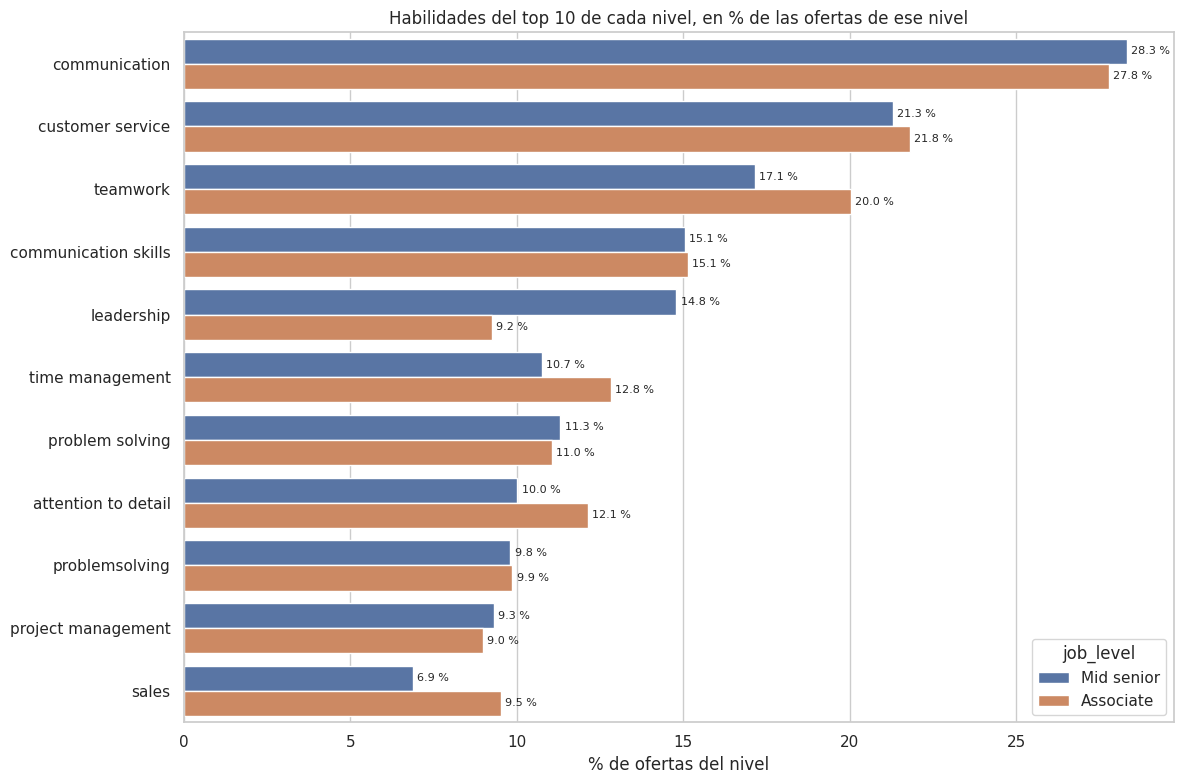

In [136]:
skills_top = [r["skill"] for r in df_skill_rows.groupBy("job_level", "skill").count()
              .withColumn("rank", F.row_number().over(ventana))
              .filter(F.col("rank") <= 10).select("skill").distinct().collect()]

por_nivel = df.groupBy("job_level").count().withColumnRenamed("count", "total_nivel")
pd_sk_nivel = df_skill_rows.filter(F.col("skill").isin(skills_top)) \
    .groupBy("job_level", "skill").count() \
    .join(por_nivel, "job_level") \
    .withColumn("pct", F.col("count") / F.col("total_nivel") * 100) \
    .toPandas()
orden = pd_sk_nivel.groupby("skill")["pct"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 8))
sns.barplot(data=pd_sk_nivel, y="skill", x="pct", hue="job_level", order=orden,
            palette=COLORES_NIVEL, ax=ax)
etiquetar_barras(ax, "{:.1f} %", tam=8)
ax.set_title("Habilidades del top 10 de cada nivel, en % de las ofertas de ese nivel")
ax.set_xlabel("% de ofertas del nivel")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Aquí uso el porcentaje dentro de cada nivel y no el conteo, porque Mid senior tiene ocho veces más ofertas y con conteos sus barras siempre serían más largas. En la mayoría de las habilidades las dos barras miden casi lo mismo, communication está en el 27.8 % de las Associate y en el 28.3 % de las Mid senior, y customer service, communication skills y problem solving tampoco cambian más de medio punto. La diferencia más grande es leadership, que aparece en el 14.8 % de las ofertas Mid senior y solo en el 9.2 % de las Associate. Del otro lado, las Associate piden un poco más teamwork, 20.0 % contra 17.1 %, time management, 12.8 % contra 10.7 %, y attention to detail, 12.1 % contra 10.0 %. También se ve que sales sí es más común en Associate, 9.5 % contra 6.9 %, mientras que project management, que en la tabla aparecía más arriba en Mid senior, en realidad tiene casi el mismo porcentaje en los dos niveles, 9.3 % contra 9.0 %. Su lugar en el ranking cambiaba solo porque las otras habilidades se reordenan. Las habilidades comunes casi no separan los niveles, entonces el modelo tiene que apoyarse en habilidades más específicas y en el título.

### 4.6 Relación con la variable objetivo

In [137]:
print("Tabla cruzada de país y nivel de puesto")
df.crosstab("search_country", "job_level").orderBy("search_country_job_level").show()

print("Porcentaje de ofertas Associate por país")
df.groupBy("search_country").agg(
    F.count("*").alias("ofertas"),
    F.round(F.mean("label") * 100, 2).alias("pct_associate")
).orderBy(F.col("ofertas").desc()).show()

print("Porcentaje de ofertas Associate por tipo de empleo")
df.groupBy("job_type").agg(
    F.count("*").alias("ofertas"),
    F.round(F.mean("label") * 100, 2).alias("pct_associate")
).orderBy(F.col("ofertas").desc()).show()

Tabla cruzada de país y nivel de puesto
+------------------------+---------+----------+
|search_country_job_level|Associate|Mid senior|
+------------------------+---------+----------+
|               Australia|     2797|     25680|
|                  Canada|     6392|     47445|
|          United Kingdom|     9368|     98984|
|           United States|   122362|    981315|
+------------------------+---------+----------+

Porcentaje de ofertas Associate por país
+--------------+-------+-------------+
|search_country|ofertas|pct_associate|
+--------------+-------+-------------+
| United States|1103677|        11.09|
|United Kingdom| 108352|         8.65|
|        Canada|  53837|        11.87|
|     Australia|  28477|         9.82|
+--------------+-------+-------------+

Porcentaje de ofertas Associate por tipo de empleo
+--------+-------+-------------+
|job_type|ofertas|pct_associate|
+--------+-------+-------------+
|  Onsite|1283529|         10.8|
|  Hybrid|   6560|        22.67|
|  Re

El porcentaje de ofertas Associate va del 8.65 % en Reino Unido al 11.87 % en Canadá, así que el país influye poco. Lo que sí cambia bastante es el tipo de empleo, las ofertas híbridas tienen 22.67 % de Associate y las remotas 20.31 %, casi el doble que las presenciales con 10.8 %.

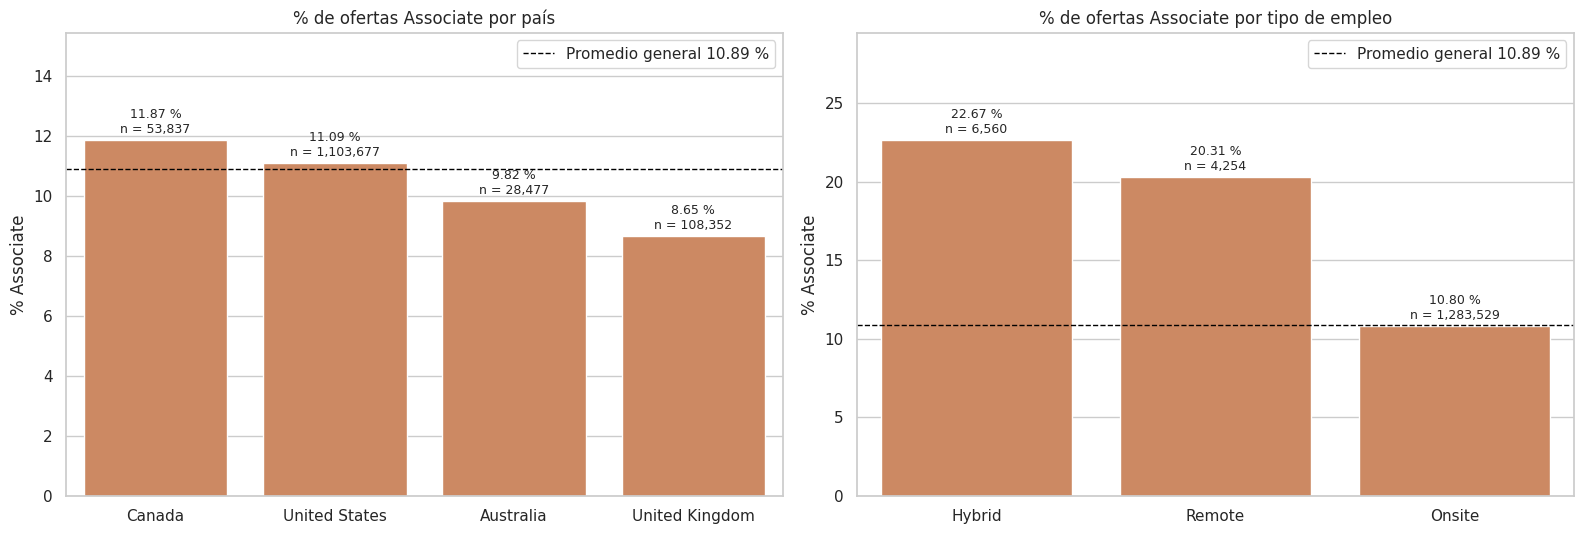

In [138]:
pct_global = df.agg(F.mean("label")).first()[0] * 100

fig, ejes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col, titulo in [(ejes[0], "search_country", "País"), (ejes[1], "job_type", "Tipo de empleo")]:
    pd_rel = df.groupBy(col).agg(F.count("*").alias("ofertas"),
                                 (F.mean("label") * 100).alias("pct_associate")) \
               .orderBy(F.col("pct_associate").desc()).toPandas()
    sns.barplot(data=pd_rel, x=col, y="pct_associate", color=COLOR_ASSOC, ax=ax)
    ax.axhline(pct_global, color="black", linestyle="--", linewidth=1,
               label=f"Promedio general {pct_global:.2f} %")
    ax.bar_label(ax.containers[0], padding=3, fontsize=9,
                 labels=[f"{p:.2f} %\nn = {n:,}" for p, n in zip(pd_rel["pct_associate"], pd_rel["ofertas"])])
    ax.set_ylim(0, pd_rel["pct_associate"].max() * 1.3)
    ax.set_title(f"% de ofertas Associate por {titulo.lower()}")
    ax.set_xlabel("")
    ax.set_ylabel("% Associate")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

La línea punteada es el 10.89 % de ofertas Associate del dataset completo. En la gráfica de países las cuatro barras quedan muy cerca de esa línea, de 8.65 % en Reino Unido a 11.87 % en Canadá, así que el país casi no cambia la probabilidad de que una oferta sea Associate. En tipo de empleo sí hay una diferencia clara, las ofertas híbridas tienen 22.67 % y las remotas 20.31 %, casi el doble que las presenciales. Pero las etiquetas con el número de ofertas muestran que híbridas y remotas son solo 6,560 y 4,254, menos del 1 % del total, por lo que esta variable ayuda en pocas ofertas. Esto explica por qué más adelante el tipo de empleo presencial aparece entre los coeficientes que empujan hacia Mid senior.

### 4.7 Conclusiones de la estadística descriptiva

Después de la limpieza quedaron 1,294,343 ofertas. La variable objetivo está desbalanceada, con 89 % Mid senior y 11 % Associate, y por eso en el modelo voy a usar pesos por clase y métricas que se fijen en la clase minoritaria, porque el accuracy por sí solo engaña. El número de habilidades y el largo del título casi no cambian entre niveles, el país influye poco y el tipo de empleo sí muestra diferencias pero el 99 % de las ofertas son presenciales. Con esto concluyo que la información más útil para predecir el nivel va a estar en el texto del título y en las habilidades específicas de cada oferta.

# Parte 5: Modelo con PySpark MLlib

El problema es de clasificación binaria. Con el título, las habilidades, el país y el tipo de empleo quiero predecir si una oferta es de nivel Associate, que es label igual a 1, o Mid senior, que es label igual a 0.

Como modelo principal uso una regresión logística. La elegí porque funciona bien con vectores de texto que tienen muchas columnas y casi todos sus valores en cero, entrena rápido con más de un millón de registros en Colab y sus coeficientes se pueden interpretar para saber qué palabras empujan hacia cada nivel. Para comparar uso Naive Bayes, que es un modelo clásico para clasificar texto.

### 5.1 Carga del dataset limpio

Leo el Parquet que guardé en la parte 3, así esta parte se puede correr sin repetir toda la limpieza.

In [139]:
df_modelo = spark.read.parquet(ruta_parquet) \
    .select("job_link", "job_title", "skills_array", "search_country", "job_type",
            "num_skills", "title_words", "label")

df_modelo.groupBy("label").count().orderBy("label").show()

+-----+-------+
|label|  count|
+-----+-------+
|    0|1153424|
|    1| 140919|
+-----+-------+



### 5.2 División en entrenamiento, validación y prueba

Divido los datos en tres conjuntos con una semilla fija:

| Conjunto | Porcentaje | Uso |
|---|---|---|
| Entrenamiento | 70 % | Ajustar las transformaciones de las variables, entrenar los modelos y hacer la validación cruzada |
| Validación | 15 % | Elegir el umbral de decisión con datos que el modelo no vio al entrenar |
| Prueba | 15 % | Medir el desempeño final una sola vez, cuando ya están tomadas todas las decisiones |

Reviso que los tres conjuntos tengan la misma proporción de clases.

In [140]:
train, val, test = df_modelo.randomSplit([0.7, 0.15, 0.15], seed=42)

for nombre, d in [("Entrenamiento", train), ("Validación", val), ("Prueba", test)]:
    n = d.count()
    pct = d.agg(F.mean("label")).first()[0] * 100
    print(f"{nombre:14s}: {n:,} registros, {pct:.2f} % Associate")

Entrenamiento : 906,678 registros, 10.90 % Associate
Validación    : 193,780 registros, 10.94 % Associate
Prueba        : 193,885 registros, 10.77 % Associate


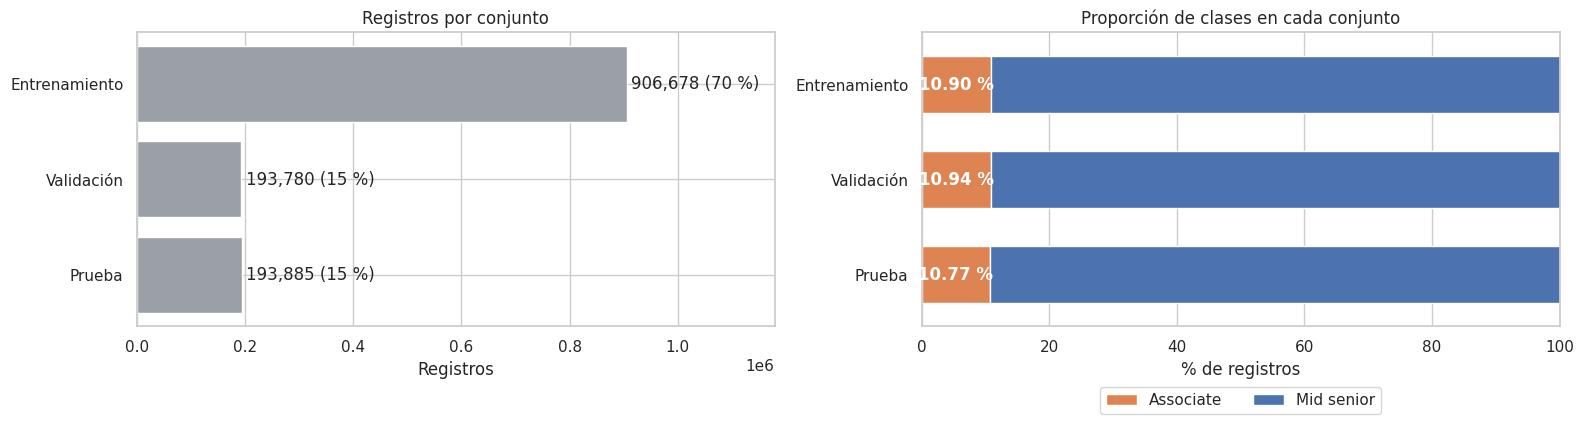

In [141]:
filas_split = []
for nombre, d in [("Entrenamiento", train), ("Validación", val), ("Prueba", test)]:
    c = {r["label"]: r["count"] for r in d.groupBy("label").count().collect()}
    filas_split.append({"conjunto": nombre, "Associate": c.get(1, 0), "Mid senior": c.get(0, 0)})
pd_split = pd.DataFrame(filas_split).set_index("conjunto")
pd_split_pct = pd_split.div(pd_split.sum(axis=1), axis=0) * 100

fig, ejes = plt.subplots(1, 2, figsize=(16, 4.5))

tamanos = pd_split.sum(axis=1)
ejes[0].barh(tamanos.index, tamanos.values, color=COLOR_GRIS)
ejes[0].bar_label(ejes[0].containers[0], labels=[f"{v:,} ({v / tamanos.sum() * 100:.0f} %)" for v in tamanos], padding=3)
ejes[0].invert_yaxis()
ejes[0].set_xlim(0, tamanos.max() * 1.3)
ejes[0].set_title("Registros por conjunto")
ejes[0].set_xlabel("Registros")

pd_split_pct[["Associate", "Mid senior"]].plot.barh(stacked=True, ax=ejes[1], color=[COLOR_ASSOC, COLOR_MID], width=0.6)
for i, v in enumerate(pd_split_pct["Associate"]):
    ejes[1].text(v / 2, i, f"{v:.2f} %", ha="center", va="center", color="white", fontweight="bold")
ejes[1].invert_yaxis()
ejes[1].set_xlim(0, 100)
ejes[1].set_title("Proporción de clases en cada conjunto")
ejes[1].set_xlabel("% de registros")
ejes[1].set_ylabel("")
ejes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)

plt.tight_layout()
plt.show()

La primera gráfica confirma que la división quedó en 70, 15 y 15 %, con 906,678 registros para entrenar y alrededor de 194 mil en validación y en prueba. En la segunda, la parte naranja mide casi lo mismo en los tres conjuntos, 10.90 %, 10.94 % y 10.77 %, que es prácticamente el 10.89 % del dataset completo. randomSplit no estratifica por clase, pero con tantos registros la proporción se mantiene sola, así que la validación y la prueba representan el mismo problema que el entrenamiento.

### 5.3 Pesos por clase

Como solo el 11 % de las ofertas son Associate, si entreno sin ajustar nada el modelo aprende a decir casi siempre Mid senior. Para evitarlo agrego una columna de peso. El peso de cada clase es el total de registros de entrenamiento entre dos veces el número de registros de esa clase, así las dos clases pesan lo mismo en el entrenamiento.

In [142]:
n_total = train.count()
n_pos = train.filter(F.col("label") == 1).count()
n_neg = n_total - n_pos

peso_pos = n_total / (2 * n_pos)
peso_neg = n_total / (2 * n_neg)
print(f"Peso Associate: {peso_pos:.3f}")
print(f"Peso Mid senior: {peso_neg:.3f}")

agregar_peso = lambda d: d.withColumn("peso", F.when(F.col("label") == 1, peso_pos).otherwise(peso_neg))
train = agregar_peso(train)
val = agregar_peso(val)
test = agregar_peso(test)

Peso Associate: 4.587
Peso Mid senior: 0.561


### 5.4 Pipeline de variables

| Variable | Transformaciones |
|---|---|
| job_title | RegexTokenizer, StopWordsRemover, CountVectorizer e IDF |
| skills_array | CountVectorizer e IDF, ya es una lista entonces cada habilidad cuenta como un término |
| search_country y job_type | StringIndexer y OneHotEncoder |
| num_skills y title_words | VectorAssembler y StandardScaler |

Al final un VectorAssembler junta todo en la columna features.

En el notebook de clase se usa HashingTF, pero yo usé CountVectorizer porque guarda el vocabulario y con eso puedo saber a qué palabra corresponde cada coeficiente del modelo. Con minDF igual a 20 ignoro los términos que aparecen en menos de 20 ofertas, que normalmente son errores de escritura o códigos de vacantes.

El pipeline lo ajusto solo con el conjunto de entrenamiento y después lo aplico a validación y prueba, para que el vocabulario y el IDF no se calculen con datos que se usan para evaluar.

In [143]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (RegexTokenizer, StopWordsRemover, CountVectorizer, IDF,
                                StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler)

etapas_features = [
    # Título
    RegexTokenizer(inputCol="job_title", outputCol="title_tokens", pattern="\\W+", minTokenLength=2),
    StopWordsRemover(inputCol="title_tokens", outputCol="title_clean"),
    CountVectorizer(inputCol="title_clean", outputCol="title_tf", vocabSize=5000, minDF=20),
    IDF(inputCol="title_tf", outputCol="title_tfidf"),
    # Habilidades
    CountVectorizer(inputCol="skills_array", outputCol="skills_tf", vocabSize=5000, minDF=20),
    IDF(inputCol="skills_tf", outputCol="skills_tfidf"),
    # Categóricas
    StringIndexer(inputCols=["search_country", "job_type"], outputCols=["country_idx", "type_idx"],
                  handleInvalid="keep"),
    OneHotEncoder(inputCols=["country_idx", "type_idx"], outputCols=["country_vec", "type_vec"],
                  handleInvalid="keep"),
    # Numéricas
    VectorAssembler(inputCols=["num_skills", "title_words"], outputCol="num_vec"),
    StandardScaler(inputCol="num_vec", outputCol="num_scaled", withMean=False, withStd=True),
    # Vector final
    VectorAssembler(inputCols=["title_tfidf", "skills_tfidf", "country_vec", "type_vec", "num_scaled"],
                    outputCol="features"),
]

import time
inicio = time.time()
modelo_features = Pipeline(stages=etapas_features).fit(train)
print(f"Pipeline de variables ajustado en {time.time() - inicio:.1f} s")

columnas = ["job_link", "features", "label", "peso"]
train_f = modelo_features.transform(train).select(*columnas).cache()
val_f = modelo_features.transform(val).select(*columnas).cache()
test_f = modelo_features.transform(test).select(*columnas).cache()

print(f"Registros de entrenamiento: {train_f.count():,}")
print(f"Registros de validación: {val_f.count():,}")
print(f"Registros de prueba: {test_f.count():,}")
print(f"Tamaño del vector de features: {train_f.first()['features'].size:,}")
print(f"Vocabulario del título: {len(modelo_features.stages[2].vocabulary):,} palabras")
print(f"Vocabulario de habilidades: {len(modelo_features.stages[4].vocabulary):,} habilidades")

Pipeline de variables ajustado en 136.6 s
Registros de entrenamiento: 906,678
Registros de validación: 193,780
Registros de prueba: 193,885
Tamaño del vector de features: 10,011
Vocabulario del título: 5,000 palabras
Vocabulario de habilidades: 5,000 habilidades


### 5.5 Función de evaluación

Por el desbalance de clases no me puedo quedar solo con el accuracy, así que reviso estas métricas:

| Métrica | Qué mide |
|---|---|
| AUC ROC | Qué tan bien ordena el modelo las ofertas de más a menos probable de ser Associate |
| AUC PR | Lo mismo pero enfocado en la clase minoritaria, es la más exigente cuando las clases están desbalanceadas |
| Precision Associate | De las ofertas que el modelo marca como Associate, cuántas sí lo son |
| Recall Associate | De las ofertas que de verdad son Associate, cuántas encuentra el modelo |
| F1 Associate | Balance entre precision y recall |
| Accuracy | Porcentaje total de aciertos |

También muestro la matriz de confusión, donde las filas son el valor real y las columnas la predicción.

Para el AUC ROC y el AUC PR uso la columna probability y no rawPrediction. El evaluador toma el segundo valor de esa columna como puntaje para ordenar las ofertas. En la regresión logística las dos columnas ordenan igual, pero en Naive Bayes rawPrediction es la log probabilidad conjunta sin normalizar, que depende mucho del número de palabras y habilidades de cada oferta, y con ella el AUC sale artificialmente cerca de 0.5. Con probability la comparación entre modelos es justa.

In [144]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator

eval_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderROC")
eval_pr = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="probability", metricName="areaUnderPR")

def evaluar(predicciones, nombre):
    def multi(metrica, **kw):
        return MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                                 metricName=metrica, **kw).evaluate(predicciones)
    tiene_raw = "probability" in predicciones.columns
    resultado = {
        "modelo": nombre,
        "auc_roc": eval_roc.evaluate(predicciones) if tiene_raw else None,
        "auc_pr": eval_pr.evaluate(predicciones) if tiene_raw else None,
        "precision_associate": multi("precisionByLabel", metricLabel=1.0),
        "recall_associate": multi("recallByLabel", metricLabel=1.0),
        "f1_associate": multi("fMeasureByLabel", metricLabel=1.0),
        "accuracy": multi("accuracy"),
    }
    print(f"\n{nombre}")
    for k, v in resultado.items():
        if k != "modelo":
            print(f"{k:22s}: {'NA' if v is None else f'{v:.4f}'}")

    print("Matriz de confusión")
    predicciones.groupBy("label").pivot("prediction", [0.0, 1.0]).count() \
        .fillna(0).orderBy("label").show()
    return resultado

resultados = []

Para las gráficas del modelo defino tres funciones. La primera calcula la matriz de confusión en Spark y la segunda la dibuja con el número de ofertas y el porcentaje de cada fila, para ver qué parte de cada clase real se clasificó bien. La tercera calcula las curvas ROC y Precision Recall. Para no pasar las casi 194 mil predicciones a pandas, en Spark agrupo las probabilidades en 500 intervalos y cuento cuántos positivos y negativos hay en cada uno, y con esos conteos acumulados calculo los puntos de las curvas.

In [145]:
from pyspark.ml.functions import vector_to_array

def matriz_confusion(pred):
    m = pred.groupBy("label", "prediction").count().toPandas()
    mat = np.zeros((2, 2), dtype=int)
    for _, r in m.iterrows():
        mat[int(r["label"]), int(r["prediction"])] = r["count"]
    return mat

def graficar_matriz(pred, titulo, ax):
    mat = matriz_confusion(pred)
    pct = mat / mat.sum(axis=1, keepdims=True) * 100
    textos = np.array([[f"{mat[i, j]:,}\n({pct[i, j]:.1f} % de la fila)" for j in range(2)] for i in range(2)])
    sns.heatmap(pct, annot=textos, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
                xticklabels=["Mid senior", "Associate"], yticklabels=["Mid senior", "Associate"],
                annot_kws={"fontsize": 11})
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(titulo)

def curvas(pred, bins=500):
    t = pred.withColumn("p1", vector_to_array("probability")[1]) \
            .withColumn("bin", F.least(F.floor(F.col("p1") * bins), F.lit(bins - 1)).cast("int")) \
            .groupBy("bin").agg(F.sum("label").alias("pos"), F.count("*").alias("n")) \
            .toPandas().sort_values("bin", ascending=False)
    t["neg"] = t["n"] - t["pos"]
    tp, fp = t["pos"].cumsum().values, t["neg"].cumsum().values
    P, N = t["pos"].sum(), t["neg"].sum()
    return {"fpr": np.concatenate([[0], fp / N]), "tpr": np.concatenate([[0], tp / P]),
            "precision": tp / (tp + fp), "recall": tp / P, "prevalencia": P / (P + N)}

### 5.6 Línea base

Antes de entrenar calculo qué pasa si siempre se predice Mid senior. Cualquier modelo que sirva tiene que superar esto en recall y F1 de Associate.

In [146]:
pred_base = test_f.withColumn("prediction", F.lit(0.0))
resultados.append(evaluar(pred_base, "Línea base siempre Mid senior"))


Línea base siempre Mid senior
auc_roc               : NA
auc_pr                : NA
precision_associate   : 0.0000
recall_associate      : 0.0000
f1_associate          : 0.0000
accuracy              : 0.8923
Matriz de confusión
+-----+------+---+
|label|   0.0|1.0|
+-----+------+---+
|    0|173009|  0|
|    1| 20876|  0|
+-----+------+---+



La línea base tiene un accuracy de casi 89 %, pero no detecta ni una sola oferta Associate. Por eso el accuracy no sirve para comparar modelos en este problema.

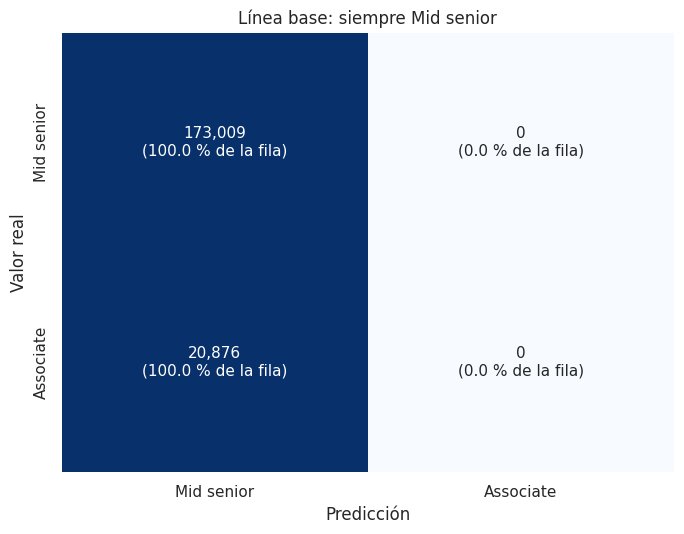

In [147]:
fig, ax = plt.subplots(figsize=(7, 5.5))
graficar_matriz(pred_base, "Línea base: siempre Mid senior", ax)
plt.tight_layout()
plt.show()

La matriz lo hace muy evidente. Toda la columna de Associate está vacía, las 173,009 ofertas Mid senior quedan bien clasificadas y las 20,876 ofertas Associate quedan todas mal, con 0 % de aciertos en su fila. El 89 % de accuracy sale solo de que Mid senior es la clase mayoritaria, por eso en las siguientes matrices me fijo sobre todo en la fila de Associate.

### 5.7 Regresión logística inicial

Entreno la regresión logística con los valores por defecto de regularización y usando la columna de pesos.

In [148]:
from pyspark.ml.classification import LogisticRegression

lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso", maxIter=50)

inicio = time.time()
modelo_lr = lr.fit(train_f)
print(f"Entrenado en {time.time() - inicio:.1f} s")

pred_lr = modelo_lr.transform(test_f)
resultados.append(evaluar(pred_lr, "Regresión logística inicial"))

Entrenado en 48.4 s

Regresión logística inicial
auc_roc               : 0.8885
auc_pr                : 0.6223
precision_associate   : 0.3442
recall_associate      : 0.7923
f1_associate          : 0.4799
accuracy              : 0.8151
Matriz de confusión
+-----+------+-----+
|label|   0.0|  1.0|
+-----+------+-----+
|    0|141496|31513|
|    1|  4336|16540|
+-----+------+-----+



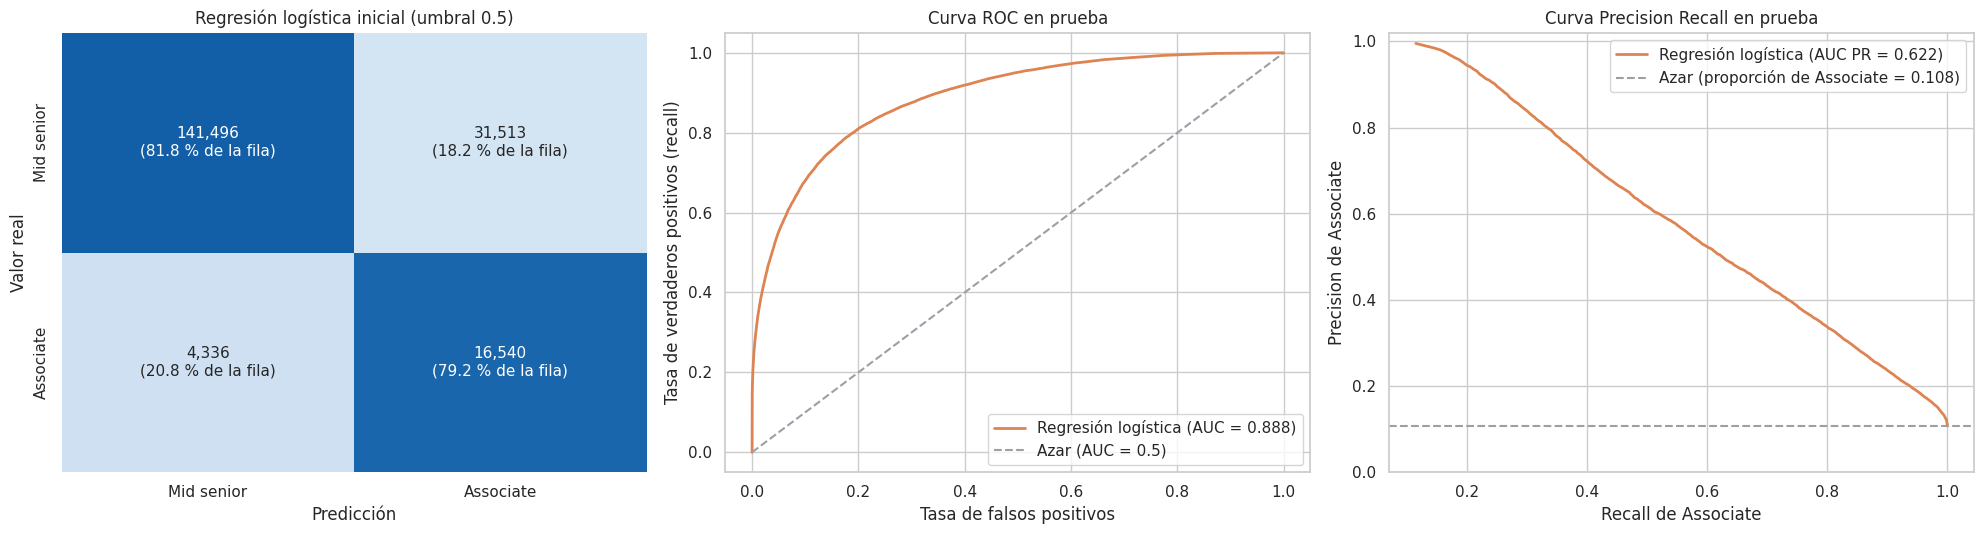

In [149]:
res = {r["modelo"]: r for r in resultados}
c_lr = curvas(pred_lr)

fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5))
graficar_matriz(pred_lr, "Regresión logística inicial (umbral 0.5)", ejes[0])

ejes[1].plot(c_lr["fpr"], c_lr["tpr"], color=COLOR_ASSOC, lw=2,
             label=f"Regresión logística (AUC = {res['Regresión logística inicial']['auc_roc']:.3f})")
ejes[1].plot([0, 1], [0, 1], "--", color=COLOR_GRIS, label="Azar (AUC = 0.5)")
ejes[1].set_xlabel("Tasa de falsos positivos")
ejes[1].set_ylabel("Tasa de verdaderos positivos (recall)")
ejes[1].set_title("Curva ROC en prueba")
ejes[1].legend(loc="lower right")

ejes[2].plot(c_lr["recall"], c_lr["precision"], color=COLOR_ASSOC, lw=2,
             label=f"Regresión logística (AUC PR = {res['Regresión logística inicial']['auc_pr']:.3f})")
ejes[2].axhline(c_lr["prevalencia"], linestyle="--", color=COLOR_GRIS,
                label=f"Azar (proporción de Associate = {c_lr['prevalencia']:.3f})")
ejes[2].set_ylim(0, 1.02)
ejes[2].set_xlabel("Recall de Associate")
ejes[2].set_ylabel("Precision de Associate")
ejes[2].set_title("Curva Precision Recall en prueba")
ejes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

En la matriz, la fila de Associate muestra que el modelo encuentra 16,548 de las 20,876 ofertas Associate, el 79.3 %. El problema está en la fila de Mid senior, donde 31,496 ofertas, el 18.2 %, se marcan como Associate por error. Como Mid senior tiene ocho veces más ofertas, esos falsos positivos son casi el doble de los aciertos de Associate, y por eso la precision es de solo 0.34.

La curva ROC queda muy por encima de la diagonal, que es lo que haría un modelo al azar, con un AUC de 0.89. La curva Precision Recall es más exigente con el desbalance, porque la línea punteada del azar está en 0.108, que es la proporción de Associate. El modelo queda muy arriba de esa línea, con un AUC PR de 0.623, casi seis veces más. La forma de la curva muestra el intercambio que ajusto más adelante con el umbral, conforme se pide más recall la precision va bajando.

### 5.8 Ajuste de hiperparámetros con validación cruzada

Uso CrossValidator con 3 folds y AUC PR como métrica para probar distintas combinaciones de regParam, que controla qué tanto se regulariza el modelo para que no se sobreajuste, y elasticNetParam, donde 0 es regularización L2, 1 es L1 y los valores intermedios mezclan las dos. La L1 además puede dejar en cero los coeficientes de variables que no sirven.

Correr 3 folds por 6 combinaciones con todo el entrenamiento en 2 núcleos tardaría demasiado, entonces la búsqueda la hago con una muestra del 20 % del entrenamiento y después vuelvo a entrenar con la mejor combinación usando el entrenamiento completo. El vocabulario y el IDF ya se calcularon con todo el entrenamiento, así que los folds comparten ese vocabulario. Lo considero aceptable porque el vocabulario no usa la etiqueta y los conjuntos de validación y prueba siguen sin usarse.

In [150]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

muestra_cv = train_f.sample(fraction=0.2, seed=42).cache()
print(f"Muestra para validación cruzada: {muestra_cv.count():,} registros")

grid = ParamGridBuilder() \
    .addGrid(lr.regParam, [0.001, 0.01, 0.1]) \
    .addGrid(lr.elasticNetParam, [0.0, 0.5]) \
    .build()

cv = CrossValidator(estimator=lr, estimatorParamMaps=grid, evaluator=eval_pr,
                    numFolds=3, seed=42, parallelism=2)

inicio = time.time()
modelo_cv = cv.fit(muestra_cv)
print(f"Validación cruzada terminada en {(time.time() - inicio) / 60:.1f} min\n")

for params, metrica in sorted(zip(grid, modelo_cv.avgMetrics), key=lambda x: -x[1]):
    print({p.name: v for p, v in params.items()}, f"AUC PR promedio: {metrica:.4f}")

mejor_reg = modelo_cv.bestModel.getRegParam()
mejor_en = modelo_cv.bestModel.getElasticNetParam()
print(f"\nMejor combinación: regParam = {mejor_reg}, elasticNetParam = {mejor_en}")
_ = muestra_cv.unpersist()

Muestra para validación cruzada: 181,992 registros
Validación cruzada terminada en 7.8 min

{'regParam': 0.001, 'elasticNetParam': 0.5} AUC PR promedio: 0.5665
{'regParam': 0.01, 'elasticNetParam': 0.5} AUC PR promedio: 0.5485
{'regParam': 0.1, 'elasticNetParam': 0.0} AUC PR promedio: 0.5416
{'regParam': 0.01, 'elasticNetParam': 0.0} AUC PR promedio: 0.5281
{'regParam': 0.001, 'elasticNetParam': 0.0} AUC PR promedio: 0.5216
{'regParam': 0.1, 'elasticNetParam': 0.5} AUC PR promedio: 0.3968

Mejor combinación: regParam = 0.001, elasticNetParam = 0.5


Vuelvo a entrenar con la mejor combinación usando todo el entrenamiento y evalúo en prueba:

In [151]:
lr_final = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso",
                              maxIter=100, regParam=mejor_reg, elasticNetParam=mejor_en)

inicio = time.time()
modelo_lr_final = lr_final.fit(train_f)
print(f"Entrenado en {time.time() - inicio:.1f} s")

pred_lr_final = modelo_lr_final.transform(test_f)
resultados.append(evaluar(pred_lr_final, "Regresión logística ajustada"))

Entrenado en 66.9 s

Regresión logística ajustada
auc_roc               : 0.8899
auc_pr                : 0.6257
precision_associate   : 0.3468
recall_associate      : 0.7944
f1_associate          : 0.4828
accuracy              : 0.8167
Matriz de confusión
+-----+------+-----+
|label|   0.0|  1.0|
+-----+------+-----+
|    0|141771|31238|
|    1|  4292|16584|
+-----+------+-----+



La validación cruzada eligió una regularización baja que mezcla L1 y L2, pero la mejora contra el modelo inicial fue muy pequeña. Esto me indica que el límite del modelo está más en la información que tienen las variables que en los hiperparámetros.

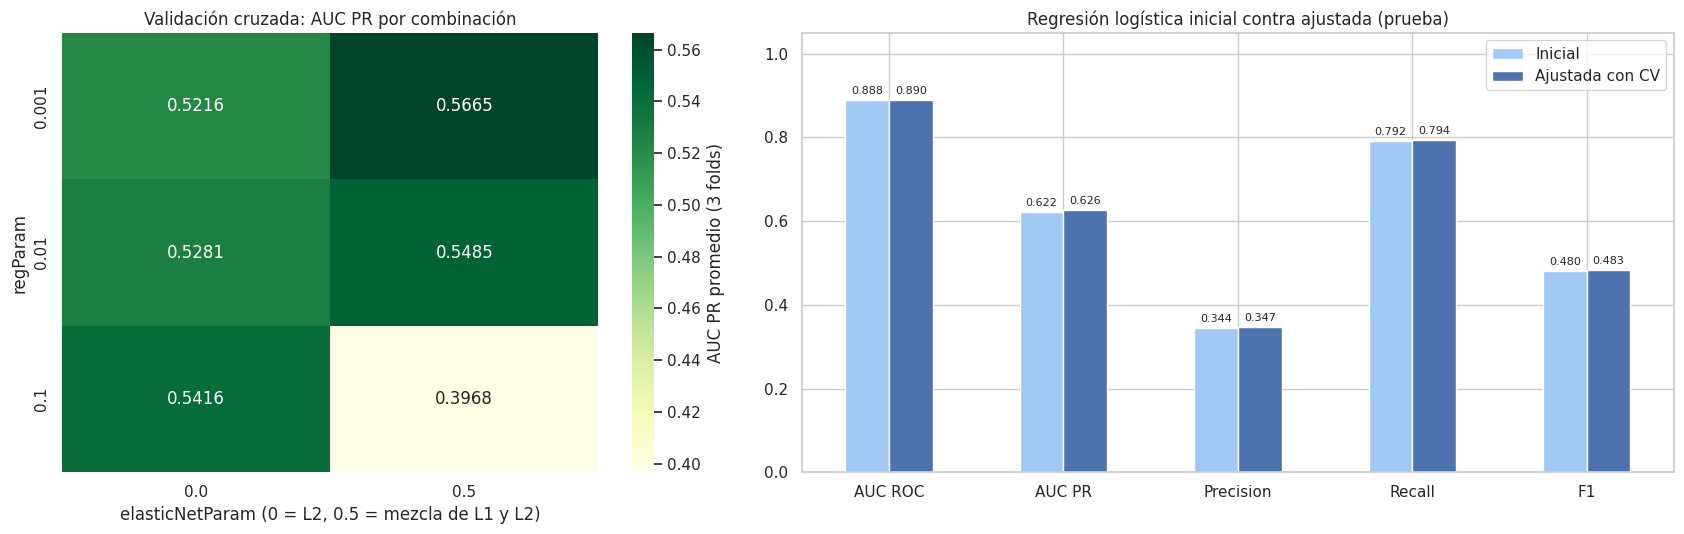

In [152]:
pd_cv = pd.DataFrame([{**{p.name: v for p, v in params.items()}, "auc_pr": m}
                      for params, m in zip(grid, modelo_cv.avgMetrics)])
tabla_cv = pd_cv.pivot(index="regParam", columns="elasticNetParam", values="auc_pr")

res = {r["modelo"]: r for r in resultados}
metricas = ["auc_roc", "auc_pr", "precision_associate", "recall_associate", "f1_associate"]
pd_comp = pd.DataFrame({"Inicial": [res["Regresión logística inicial"][m] for m in metricas],
                        "Ajustada con CV": [res["Regresión logística ajustada"][m] for m in metricas]},
                       index=["AUC ROC", "AUC PR", "Precision", "Recall", "F1"])

fig, ejes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1, 1.3]})
sns.heatmap(tabla_cv, annot=True, fmt=".4f", cmap="YlGn", ax=ejes[0],
            cbar_kws={"label": "AUC PR promedio (3 folds)"})
ejes[0].set_title("Validación cruzada: AUC PR por combinación")
ejes[0].set_xlabel("elasticNetParam (0 = L2, 0.5 = mezcla de L1 y L2)")
ejes[0].set_ylabel("regParam")

pd_comp.plot.bar(ax=ejes[1], color=["#A1C9F4", COLOR_MID], rot=0)
etiquetar_barras(ejes[1], "{:.3f}", tam=8)
ejes[1].set_ylim(0, 1.05)
ejes[1].set_title("Regresión logística inicial contra ajustada (prueba)")
ejes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

En el mapa de calor la mejor celda es regParam 0.001 con elasticNetParam 0.5, con un AUC PR de 0.5669, y la peor es regParam 0.1 con la misma mezcla, con 0.3968. Esto pasa porque con una regularización fuerte la parte L1 deja en cero demasiados coeficientes y el modelo pierde información. Con L2 pura, la columna de la izquierda, los resultados son más parejos, entre 0.52 y 0.54. Los valores de la validación cruzada son más bajos que los de prueba porque cada fold entrena solo con dos tercios de la muestra del 20 %.

En la gráfica de la derecha las barras del modelo inicial y del ajustado casi miden lo mismo, el AUC PR pasa de 0.623 a 0.626 y el F1 de 0.480 a 0.483. Esto confirma que ajustar los hiperparámetros casi no cambió el resultado y que el límite está en la información de las variables.

### 5.9 Naive Bayes

Naive Bayes multinomial solo acepta variables positivas. El TF IDF, el one hot encoding y el escalado sin centrar cumplen con eso, entonces puedo usar el mismo vector de features.

In [153]:
from pyspark.ml.classification import NaiveBayes

nb = NaiveBayes(featuresCol="features", labelCol="label", weightCol="peso",
                modelType="multinomial", smoothing=1.0)

inicio = time.time()
modelo_nb = nb.fit(train_f)
print(f"Entrenado en {time.time() - inicio:.1f} s")

pred_nb = modelo_nb.transform(test_f)
resultados.append(evaluar(pred_nb, "Naive Bayes"))

Entrenado en 7.1 s

Naive Bayes
auc_roc               : 0.8234
auc_pr                : 0.4119
precision_associate   : 0.2386
recall_associate      : 0.7767
f1_associate          : 0.3651
accuracy              : 0.7091
Matriz de confusión
+-----+------+-----+
|label|   0.0|  1.0|
+-----+------+-----+
|    0|121275|51734|
|    1|  4662|16214|
+-----+------+-----+



Naive Bayes quedó por debajo de la regresión logística en todas las métricas, con un AUC ROC de 0.82 contra 0.89 y un AUC PR de 0.41 contra 0.63. Sí ordena las ofertas mejor que el azar, pero con el umbral de 0.5 marca como Associate a muchas más ofertas Mid senior, y por eso su precision es de solo 0.24. Este modelo supone que todas las variables son independientes entre sí, y en este caso no se cumple porque muchas palabras del título y muchas habilidades aparecen juntas. Al sumar como independientes variables que en realidad dicen lo mismo, el modelo se vuelve demasiado seguro y da probabilidades muy pegadas a 0 o a 1.

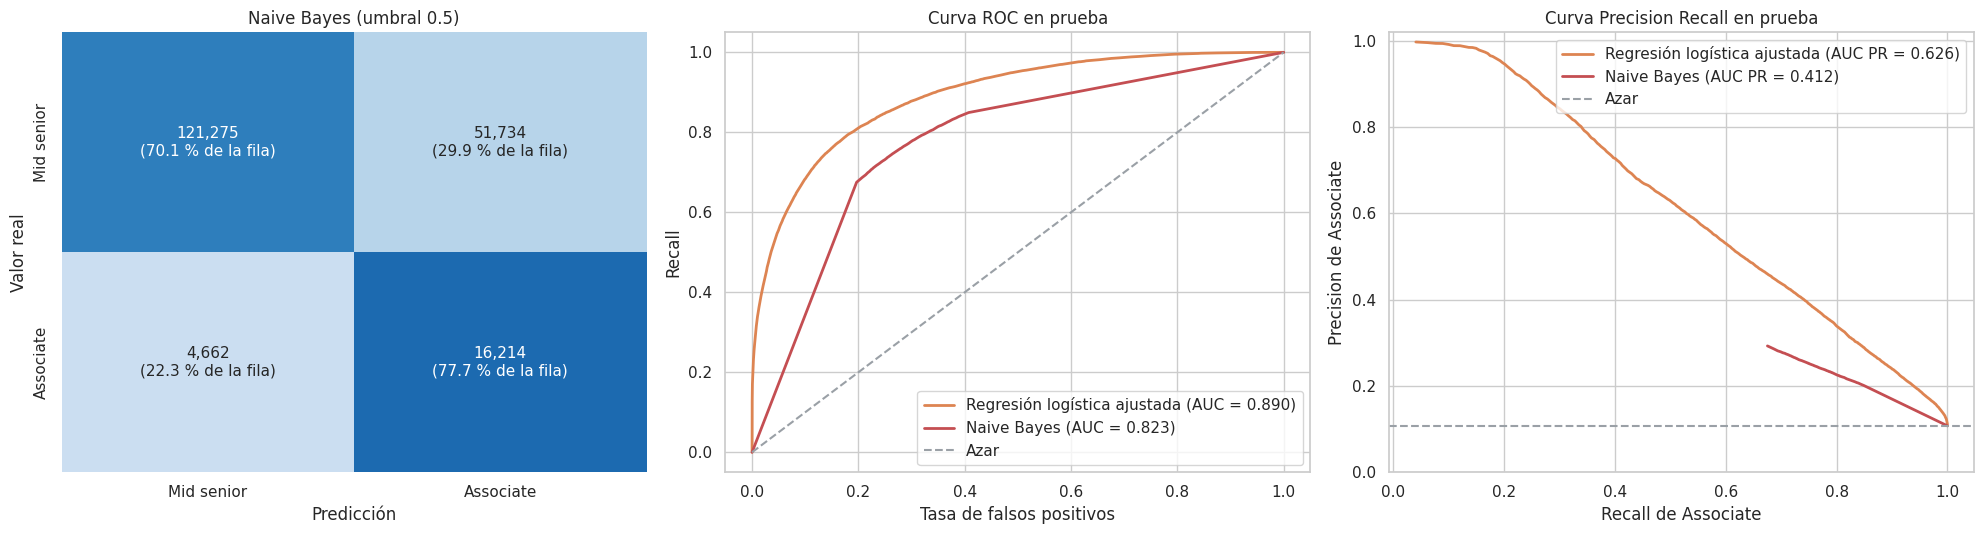

In [154]:
res = {r["modelo"]: r for r in resultados}
c_nb = curvas(pred_nb)
c_lrf = curvas(pred_lr_final)

fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5))
graficar_matriz(pred_nb, "Naive Bayes (umbral 0.5)", ejes[0])

for c, nombre, color in [(c_lrf, "Regresión logística ajustada", COLOR_ASSOC), (c_nb, "Naive Bayes", "#C44E52")]:
    ejes[1].plot(c["fpr"], c["tpr"], color=color, lw=2, label=f"{nombre} (AUC = {res[nombre]['auc_roc']:.3f})")
    ejes[2].plot(c["recall"], c["precision"], color=color, lw=2, label=f"{nombre} (AUC PR = {res[nombre]['auc_pr']:.3f})")
ejes[1].plot([0, 1], [0, 1], "--", color=COLOR_GRIS, label="Azar")
ejes[2].axhline(c_nb["prevalencia"], linestyle="--", color=COLOR_GRIS, label="Azar")
ejes[1].set_title("Curva ROC en prueba")
ejes[1].set_xlabel("Tasa de falsos positivos")
ejes[1].set_ylabel("Recall")
ejes[1].legend(loc="lower right")
ejes[2].set_title("Curva Precision Recall en prueba")
ejes[2].set_xlabel("Recall de Associate")
ejes[2].set_ylabel("Precision de Associate")
ejes[2].set_ylim(0, 1.02)
ejes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

En la matriz, Naive Bayes encuentra 16,214 ofertas Associate, el 77.7 %, casi lo mismo que la regresión logística. La diferencia está en la fila de Mid senior, donde marca como Associate a 51,717 ofertas, el 29.9 %, contra el 18.0 % de la regresión logística.

En la curva ROC, Naive Bayes queda claramente arriba de la diagonal del azar, con un AUC de 0.823, pero por debajo de la regresión logística en todo el recorrido, que tiene 0.890. Su curva está formada por pocos tramos rectos porque el modelo da probabilidades casi siempre pegadas a 0 o a 1, y entonces hay pocos valores distintos para ordenar las ofertas. Eso se nota más en la curva Precision Recall. La curva de Naive Bayes empieza hasta un recall cercano a 0.7 con una precision de apenas 0.3, es decir, casi siete de cada diez ofertas Associate reciben una probabilidad prácticamente igual a 1, pero junto con ellas también muchas Mid senior, y el modelo no tiene forma de distinguirlas entre sí. Su AUC PR es de 0.412, casi cuatro veces el 0.108 del azar pero lejos del 0.626 de la regresión logística.

### 5.10 Umbral de decisión

Por defecto el modelo dice que una oferta es Associate cuando la probabilidad es mayor a 0.5. Como entrené con pesos, el modelo tiende a marcar demasiadas ofertas como Associate, lo que sube el recall pero baja mucho la precision. Pruebo varios umbrales con el conjunto de validación y me quedo con el que da el mejor F1. Lo hago con validación y no con prueba para que la evaluación final no esté sesgada.

In [155]:
from pyspark.ml.functions import vector_to_array

val_pred = modelo_lr_final.transform(val_f) \
    .withColumn("p1", vector_to_array("probability")[1]).select("label", "p1").cache()

filas = []
for u in [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85]:
    m = val_pred.agg(
        F.sum(((F.col("p1") >= u) & (F.col("label") == 1)).cast("int")).alias("tp"),
        F.sum(((F.col("p1") >= u) & (F.col("label") == 0)).cast("int")).alias("fp"),
        F.sum(((F.col("p1") < u) & (F.col("label") == 1)).cast("int")).alias("fn"),
    ).first()
    p = m.tp / (m.tp + m.fp) if (m.tp + m.fp) else 0.0
    r = m.tp / (m.tp + m.fn) if (m.tp + m.fn) else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) else 0.0
    filas.append((u, round(p, 4), round(r, 4), round(f1, 4)))

df_umbral = spark.createDataFrame(filas, ["umbral", "precision", "recall", "f1"])
print("Resultados en validación")
df_umbral.show()
mejor_umbral = df_umbral.orderBy(F.col("f1").desc()).first()["umbral"]
print("Mejor umbral por F1:", mejor_umbral)
_ = val_pred.unpersist()

modelo_lr_final.setThreshold(mejor_umbral)
pred_umbral = modelo_lr_final.transform(test_f)
resultados.append(evaluar(pred_umbral, f"Regresión logística con umbral {mejor_umbral}"))

Resultados en validación
+------+---------+------+------+
|umbral|precision|recall|    f1|
+------+---------+------+------+
|   0.5|   0.3503|0.7952|0.4863|
|  0.55|   0.3859|0.7613|0.5122|
|   0.6|   0.4252|0.7203|0.5347|
|  0.65|   0.4694|0.6711|0.5524|
|   0.7|   0.5246|0.6151|0.5663|
|  0.75|     0.59|0.5504|0.5695|
|   0.8|   0.6602|0.4718|0.5503|
|  0.85|   0.7459|0.3887|0.5111|
+------+---------+------+------+

Mejor umbral por F1: 0.75

Regresión logística con umbral 0.75
auc_roc               : 0.8899
auc_pr                : 0.6257
precision_associate   : 0.5812
recall_associate      : 0.5491
f1_associate          : 0.5647
accuracy              : 0.9089
Matriz de confusión
+-----+------+-----+
|label|   0.0|  1.0|
+-----+------+-----+
|    0|164751| 8258|
|    1|  9414|11462|
+-----+------+-----+



Al subir el umbral el modelo marca menos ofertas como Associate, entonces la precision sube y el recall baja. El mejor F1 en validación fue con un umbral de 0.75. En prueba, con ese umbral la precision subió de 0.35 a 0.58 y el F1 de 0.48 a 0.56, pero el recall bajó de 0.79 a 0.55, o sea que ahora el modelo se equivoca menos cuando dice que una oferta es Associate pero deja pasar más ofertas Associate sin detectarlas. El accuracy subió a 0.909 y ya supera a la línea base. El AUC ROC y el AUC PR no cambian porque no dependen del umbral, solo de cómo ordena el modelo las probabilidades. Este umbral es el que se queda guardado en el modelo final.

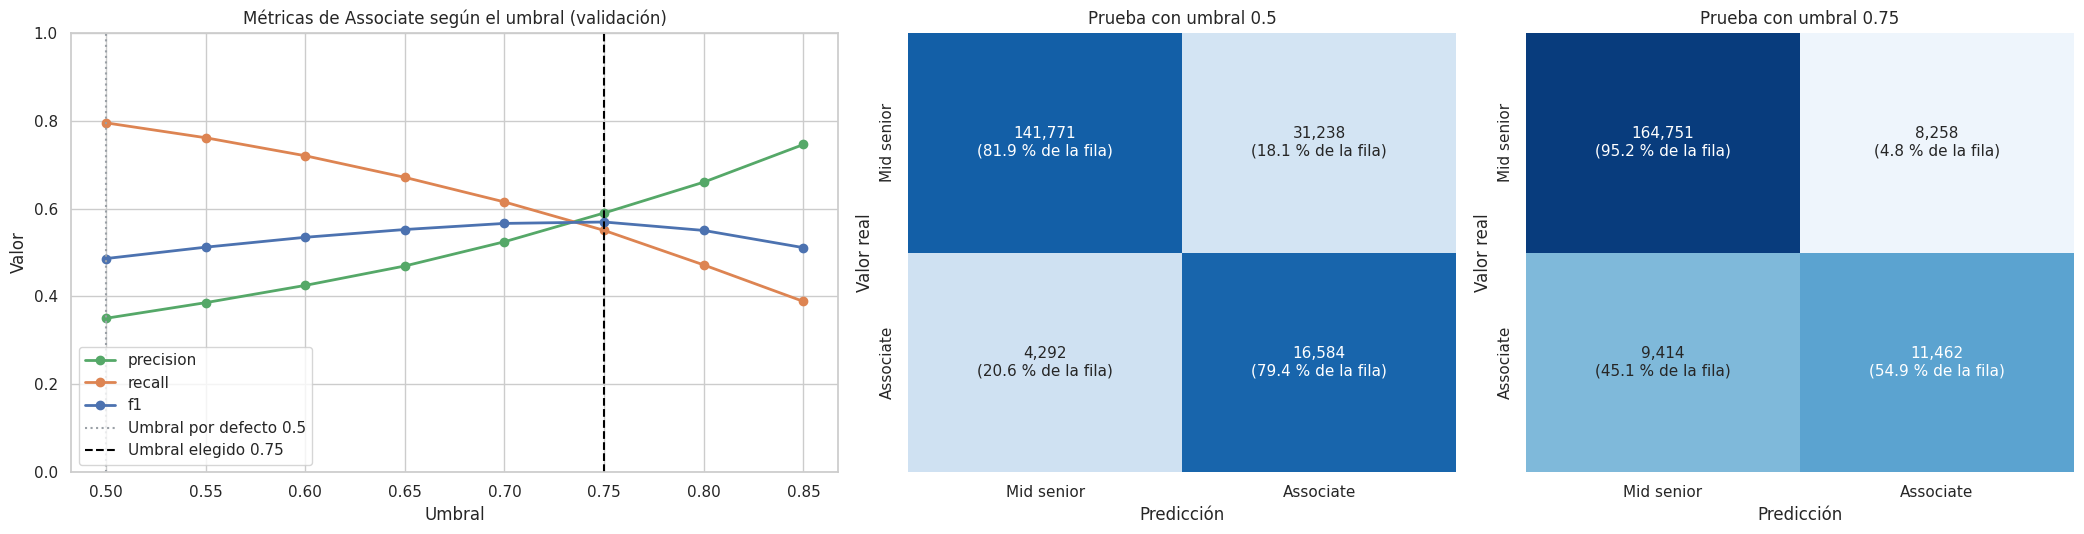

In [156]:
pd_umb = df_umbral.toPandas()
pred_05 = pred_lr_final.withColumn("prediction", (vector_to_array("probability")[1] > 0.5).cast("double"))

fig, ejes = plt.subplots(1, 3, figsize=(21, 5.5), gridspec_kw={"width_ratios": [1.4, 1, 1]})
for metrica, color in [("precision", "#55A868"), ("recall", COLOR_ASSOC), ("f1", COLOR_MID)]:
    ejes[0].plot(pd_umb["umbral"], pd_umb[metrica], marker="o", lw=2, color=color, label=metrica)
ejes[0].axvline(0.5, linestyle=":", color=COLOR_GRIS, label="Umbral por defecto 0.5")
ejes[0].axvline(mejor_umbral, linestyle="--", color="black", label=f"Umbral elegido {mejor_umbral}")
ejes[0].set_ylim(0, 1)
ejes[0].set_title("Métricas de Associate según el umbral (validación)")
ejes[0].set_xlabel("Umbral")
ejes[0].set_ylabel("Valor")
ejes[0].legend(loc="lower left")

graficar_matriz(pred_05, "Prueba con umbral 0.5", ejes[1])
graficar_matriz(pred_umbral, f"Prueba con umbral {mejor_umbral}", ejes[2])

plt.tight_layout()
plt.show()

En la gráfica de líneas se ve el intercambio entre las dos métricas. Al subir el umbral la precision sube de 0.35 a 0.75 y el recall baja de 0.80 a 0.39. El F1 forma un arco bastante plano, entre 0.65 y 0.80 se queda entre 0.55 y 0.57, y su máximo es 0.570 en 0.75, cerca de donde se cruzan la precision y el recall. Que el arco sea plano quiere decir que no importa tanto elegir exactamente 0.75, cualquier valor en esa zona da resultados parecidos.

Las dos matrices muestran el efecto en prueba. Con 0.5 hay 31,214 ofertas Mid senior marcadas como Associate por error y con 0.75 bajan a 8,271, un 74 % menos. A cambio, las ofertas Associate que sí se detectan bajan de 16,578 a 11,464, o sea de 79.4 % a 54.9 % de su fila.

### 5.11 Comparación de modelos

In [157]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

esquema_res = StructType([StructField("modelo", StringType())] +
                         [StructField(k, DoubleType()) for k in
                          ["auc_roc", "auc_pr", "precision_associate", "recall_associate", "f1_associate", "accuracy"]])

df_resultados = spark.createDataFrame(resultados, schema=esquema_res)
df_resultados.select("modelo", *[F.round(c, 4).alias(c) for c in df_resultados.columns[1:]]) \
    .show(truncate=False)

+-----------------------------------+-------+------+-------------------+----------------+------------+--------+
|modelo                             |auc_roc|auc_pr|precision_associate|recall_associate|f1_associate|accuracy|
+-----------------------------------+-------+------+-------------------+----------------+------------+--------+
|Línea base siempre Mid senior      |NULL   |NULL  |0.0                |0.0             |0.0         |0.8923  |
|Regresión logística inicial        |0.8885 |0.6223|0.3442             |0.7923          |0.4799      |0.8151  |
|Regresión logística ajustada       |0.8899 |0.6257|0.3468             |0.7944          |0.4828      |0.8167  |
|Naive Bayes                        |0.8234 |0.4119|0.2386             |0.7767          |0.3651      |0.7091  |
|Regresión logística con umbral 0.75|0.8899 |0.6257|0.5812             |0.5491          |0.5647      |0.9089  |
+-----------------------------------+-------+------+-------------------+----------------+------------+--

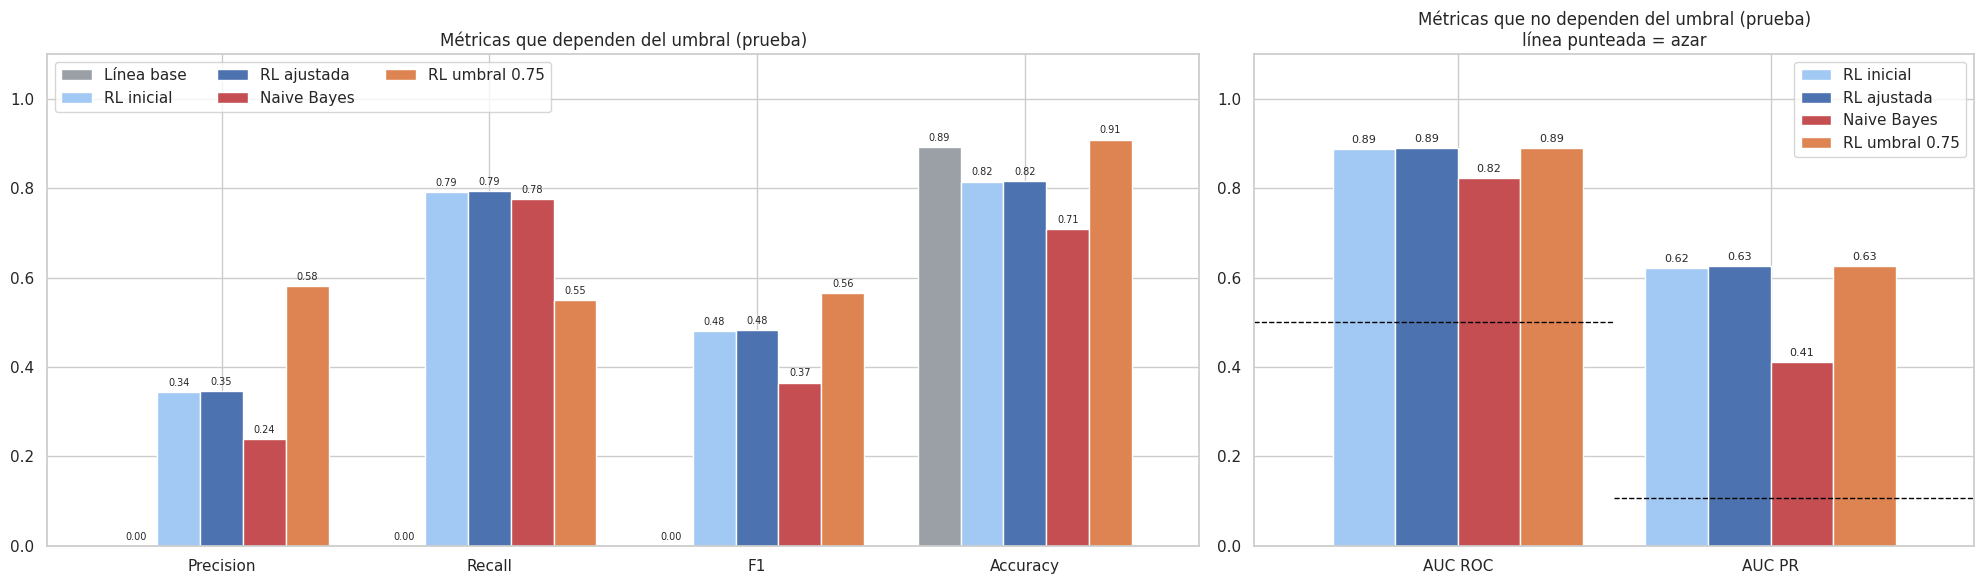

In [158]:
pd_res = df_resultados.toPandas().set_index("modelo")
cortos = {"Línea base siempre Mid senior": "Línea base", "Regresión logística inicial": "RL inicial",
          "Regresión logística ajustada": "RL ajustada", "Naive Bayes": "Naive Bayes"}
pd_res.index = [cortos.get(m, f"RL umbral {mejor_umbral}") for m in pd_res.index]
colores_mod = [COLOR_GRIS, "#A1C9F4", COLOR_MID, "#C44E52", COLOR_ASSOC]

fig, ejes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={"width_ratios": [1.6, 1]})

izq = pd_res[["precision_associate", "recall_associate", "f1_associate", "accuracy"]]
izq.columns = ["Precision", "Recall", "F1", "Accuracy"]
izq.T.plot.bar(ax=ejes[0], color=colores_mod, rot=0, width=0.8)
etiquetar_barras(ejes[0], "{:.2f}", tam=7)
ejes[0].set_ylim(0, 1.1)
ejes[0].set_title("Métricas que dependen del umbral (prueba)")
ejes[0].legend(loc="upper left", ncol=3)

der = pd_res.drop(index="Línea base")[["auc_roc", "auc_pr"]]
der.columns = ["AUC ROC", "AUC PR"]
der.T.plot.bar(ax=ejes[1], color=colores_mod[1:], rot=0, width=0.8)
etiquetar_barras(ejes[1], "{:.2f}", tam=8)
ejes[1].axhline(0.5, xmin=0, xmax=0.5, linestyle="--", color="black", linewidth=1)
prevalencia_test = test_f.agg(F.mean("label")).first()[0]
ejes[1].axhline(prevalencia_test, xmin=0.5, xmax=1, linestyle="--", color="black", linewidth=1)
ejes[1].set_ylim(0, 1.1)
ejes[1].set_title("Métricas que no dependen del umbral (prueba)\nlínea punteada = azar")
ejes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

En la gráfica de la izquierda la línea base tiene una de las barras de accuracy más altas, 0.89, pero sus barras de precision, recall y F1 están en cero, que es justo por lo que el accuracy no sirve para comparar en este problema. Los modelos con umbral 0.5 tienen un recall parecido, entre 0.78 y 0.79, y lo que los separa es la precision, 0.24 en Naive Bayes contra 0.34 y 0.35 en las regresiones logísticas. La regresión logística con umbral 0.75 es el único modelo con precision y recall equilibrados, 0.58 y 0.55, y tiene el F1 más alto, 0.56, y el accuracy más alto, 0.91.

En la gráfica de la derecha las tres barras de regresión logística miden lo mismo, 0.89 de AUC ROC y 0.63 de AUC PR, porque el umbral no cambia el orden de las probabilidades y la validación cruzada casi no movió el modelo. Naive Bayes queda por debajo, con 0.82 de AUC ROC y 0.41 de AUC PR. Supera claramente a las líneas del azar, pero la distancia contra la regresión logística es mucho mayor en AUC PR, que es la métrica que se fija en la clase minoritaria.

### 5.12 Interpretación del modelo

Relaciono cada coeficiente de la regresión logística con la palabra o habilidad que representa, usando los metadatos del vector features y el vocabulario de los CountVectorizer. Un coeficiente positivo aumenta la probabilidad de que la oferta sea Associate y uno negativo la empuja hacia Mid senior.

In [159]:
atributos = train_f.schema["features"].metadata["ml_attr"]["attrs"]
nombres = {a["idx"]: a["name"] for grupo in atributos.values() for a in grupo}

vocab_titulo = modelo_features.stages[2].vocabulary
vocab_skills = modelo_features.stages[4].vocabulary

def traducir(nombre):
    if nombre.startswith("title_tfidf_"):
        return "título", vocab_titulo[int(nombre.rsplit("_", 1)[1])]
    if nombre.startswith("skills_tfidf_"):
        return "habilidad", vocab_skills[int(nombre.rsplit("_", 1)[1])]
    if nombre.startswith("country_vec_"):
        return "país", nombre.replace("country_vec_", "")
    if nombre.startswith("type_vec_"):
        return "tipo empleo", nombre.replace("type_vec_", "")
    return "numérica", {"num_scaled_0": "num_skills", "num_scaled_1": "title_words"}.get(nombre, nombre)

coefs = modelo_lr_final.coefficients.toArray()
filas = [(*traducir(nombres[i]), float(c)) for i, c in enumerate(coefs) if c != 0.0]
df_coefs = spark.createDataFrame(filas, ["tipo", "termino", "coeficiente"])

print(f"Variables con coeficiente distinto de cero: {df_coefs.count():,} de {len(coefs):,}")
print("\nVariables que más indican Associate")
df_coefs.orderBy(F.col("coeficiente").desc()).show(15, truncate=False)
print("Variables que más indican Mid senior")
df_coefs.orderBy(F.col("coeficiente").asc()).show(15, truncate=False)

Variables con coeficiente distinto de cero: 6,498 de 10,011

Variables que más indican Associate
+---------+----------------------------------------------------+-------------------+
|tipo     |termino                                             |coeficiente        |
+---------+----------------------------------------------------+-------------------+
|título   |volunteer                                           |0.8460929388262425 |
|habilidad|video game knowledge                                |0.552870264733632  |
|habilidad|aha basic health care life support hcp certification|0.47241278717946183|
|título   |cosmetology                                         |0.4528458264739064 |
|título   |tpwd                                                |0.440227333470274  |
|habilidad|social work qualification                           |0.435838084528644  |
|título   |associate                                           |0.4250120951463137 |
|título   |prep                                      

Gracias a la regularización L1 varias variables quedaron con coeficiente cero, o sea que el modelo las descartó. Las palabras del título son las que más pesan. Hacia Mid senior empujan manager, lead, senior y supervisor, que son palabras que tienen sentido para un puesto con más experiencia o a cargo de un equipo. Hacia Associate aparecen volunteer, associate, culinary y prep, que se relacionan con puestos de entrada o de apoyo. El tipo de empleo presencial también empuja hacia Mid senior, lo que coincide con lo que vi en la estadística descriptiva.

También aparecen términos como siglas de dependencias o nombres de empresas, que no describen el puesto sino a un empleador en específico. Esto quiere decir que el modelo aprendió algunos patrones de empresas que publican muchas ofertas de un solo nivel, y es algo que tendría que tomar en cuenta si se quisiera usar con datos de otras empresas.

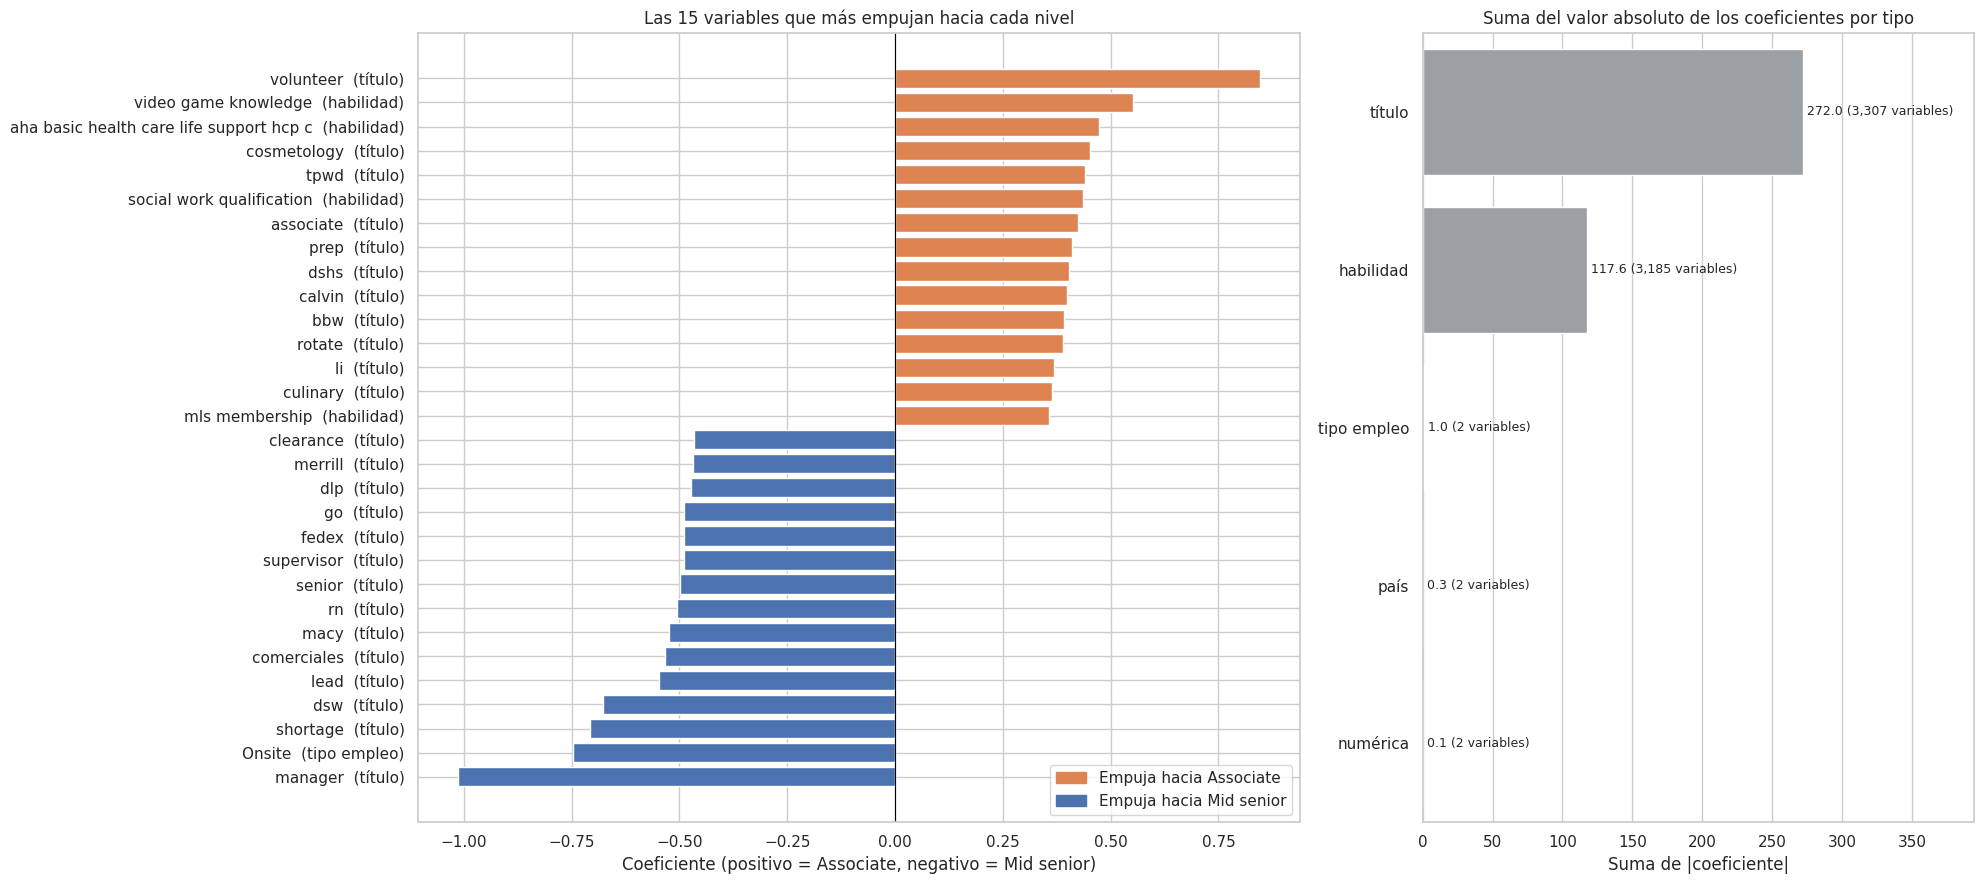

In [160]:
pd_pos = df_coefs.orderBy(F.col("coeficiente").desc()).limit(15).toPandas()
pd_neg = df_coefs.orderBy(F.col("coeficiente").asc()).limit(15).toPandas()
pd_top_c = pd.concat([pd_pos, pd_neg]).sort_values("coeficiente")
pd_top_c["etiqueta"] = pd_top_c["termino"].str.slice(0, 40) + "  (" + pd_top_c["tipo"] + ")"

pd_tipos = df_coefs.groupBy("tipo").agg(F.count("*").alias("variables"),
                                         F.sum(F.abs("coeficiente")).alias("peso_total")) \
                   .orderBy(F.col("peso_total").desc()).toPandas()

fig, ejes = plt.subplots(1, 2, figsize=(20, 9), gridspec_kw={"width_ratios": [1.6, 1]})

ejes[0].barh(pd_top_c["etiqueta"], pd_top_c["coeficiente"],
             color=[COLOR_ASSOC if c > 0 else COLOR_MID for c in pd_top_c["coeficiente"]])
ejes[0].axvline(0, color="black", linewidth=0.8)
ejes[0].set_title("Las 15 variables que más empujan hacia cada nivel")
ejes[0].set_xlabel("Coeficiente (positivo = Associate, negativo = Mid senior)")
ejes[0].legend(handles=[Patch(color=COLOR_ASSOC, label="Empuja hacia Associate"),
                        Patch(color=COLOR_MID, label="Empuja hacia Mid senior")], loc="lower right")

sns.barplot(data=pd_tipos, y="tipo", x="peso_total", color=COLOR_GRIS, ax=ejes[1])
ejes[1].bar_label(ejes[1].containers[0], padding=3, fontsize=9,
                  labels=[f"{v:,.1f} ({n:,} variables)" for v, n in zip(pd_tipos["peso_total"], pd_tipos["variables"])])
ejes[1].set_xlim(0, pd_tipos["peso_total"].max() * 1.45)
ejes[1].set_title("Suma del valor absoluto de los coeficientes por tipo")
ejes[1].set_xlabel("Suma de |coeficiente|")
ejes[1].set_ylabel("")

plt.tight_layout()
plt.show()

En la gráfica de la izquierda la barra más larga es manager, con −1.01, seguida del tipo de empleo presencial con −0.75, las dos hacia Mid senior. Hacia Associate la más fuerte es volunteer, con 0.85, y después aparecen dos habilidades, video game knowledge y la certificación de soporte vital básico. La mayoría de las 30 barras son palabras del título, lo que confirma que el título es la fuente de información más útil. También se ven barras de nombres de empresas o siglas de dependencias, como macy, fedex, calvin, bbw, tpwd y dshs, que no describen el puesto sino a un empleador que publica muchas ofertas de un mismo nivel.

La gráfica de la derecha muestra cuánto pesa cada tipo de variable en total. De las 10,011 variables, 6,511 quedaron con coeficiente distinto de cero, 3,315 del título y 3,190 de habilidades. Aunque los dos grupos tienen casi el mismo número de variables, el título suma alrededor de 272 contra 117 de las habilidades, más del doble. El país, el tipo de empleo y las variables numéricas casi no aportan, con sumas de 1.0 o menos, porque son solo dos columnas cada uno.

### 5.13 Guardado del modelo

Uno el pipeline de variables con la regresión logística final en un solo PipelineModel. Así el modelo guardado recibe los datos con el mismo formato del dataset limpio y hace todas las transformaciones solo. Después lo vuelvo a cargar para comprobar que da el mismo resultado.

In [161]:
modelo_completo = PipelineModel(stages=modelo_features.stages + [modelo_lr_final])

ruta_modelo = os.path.join(carpeta_salida, "modelo_job_level_lr")
modelo_completo.write().overwrite().save(ruta_modelo)
print("Modelo guardado en:", ruta_modelo)

modelo_cargado = PipelineModel.load(ruta_modelo)
auc_recargado = eval_pr.evaluate(modelo_cargado.transform(test))
print(f"AUC PR del modelo recargado: {auc_recargado:.4f}")

Modelo guardado en: /content/drive/MyDrive/portafolio_bigdata/modelo_job_level_lr
AUC PR del modelo recargado: 0.6257


# Parte 6: Predicciones con datos nuevos

Pruebo el modelo guardado con ofertas que inventé y que no están en el dataset. Antes de pasarlas al modelo les aplico la misma limpieza de la parte 3, es decir, el título en minúsculas, las habilidades como lista y los conteos.

In [162]:
def preparar_nuevas(d):
    return d.withColumn("job_title", F.regexp_replace(F.lower(F.trim("job_title")), r"\s+", " ")) \
            .withColumn("skills_array",
                        F.array_distinct(F.filter(
                            F.transform(F.split(F.lower("job_skills"), ","), lambda s: F.trim(s)),
                            lambda s: s != ""))) \
            .withColumn("num_skills", F.size("skills_array")) \
            .withColumn("title_words", F.size(F.split("job_title", " ")))

ofertas_nuevas = spark.createDataFrame([
    ("Junior Data Analyst", "SQL, Excel, Data analysis, Communication", "United States", "Onsite"),
    ("Senior Software Engineer", "Python, AWS, Kubernetes, System design, Leadership, Mentoring", "United States", "Hybrid"),
    ("Retail Sales Associate", "Customer service, Cash handling, Sales, Teamwork", "Canada", "Onsite"),
    ("Director of Nursing", "Nursing, Leadership, Budget management, Patient care, Staff development", "United Kingdom", "Onsite"),
    ("Entry Level Accountant", "Accounting, Excel, QuickBooks, Attention to detail", "Australia", "Onsite"),
    ("Operations Manager", "Operations management, Leadership, Budgeting, Process improvement", "United States", "Onsite"),
], ["job_title", "job_skills", "search_country", "job_type"])

pred_nuevas = modelo_cargado.transform(preparar_nuevas(ofertas_nuevas)) \
    .withColumn("prob_associate", F.round(vector_to_array("probability")[1], 3)) \
    .withColumn("prediccion", F.when(F.col("prediction") == 1, "Associate").otherwise("Mid senior"))

pred_nuevas.select("job_title", "search_country", "num_skills", "prob_associate", "prediccion") \
    .show(truncate=False)

+------------------------+--------------+----------+--------------+----------+
|job_title               |search_country|num_skills|prob_associate|prediccion|
+------------------------+--------------+----------+--------------+----------+
|junior data analyst     |United States |4         |0.837         |Associate |
|senior software engineer|United States |6         |0.435         |Mid senior|
|retail sales associate  |Canada        |4         |0.859         |Associate |
|director of nursing     |United Kingdom|5         |0.257         |Mid senior|
|entry level accountant  |Australia     |4         |0.719         |Mid senior|
|operations manager      |United States |4         |0.208         |Mid senior|
+------------------------+--------------+----------+--------------+----------+



La mayoría de las predicciones tienen sentido. El analista junior y el vendedor de tienda salen como Associate con probabilidades arriba de 0.83, y el director, el gerente de operaciones y el ingeniero senior salen como Mid senior. El contador de nivel de entrada salió como Mid senior aunque su probabilidad de ser Associate fue de 0.72, porque quedó apenas debajo del umbral de 0.75. Esto muestra el efecto de subir el umbral, el modelo es más estricto para marcar una oferta como Associate. El ingeniero senior tiene una probabilidad de 0.43, más alta que la del director o la del gerente, probablemente porque es híbrido y las habilidades técnicas también aparecen en ofertas de nivel Associate.

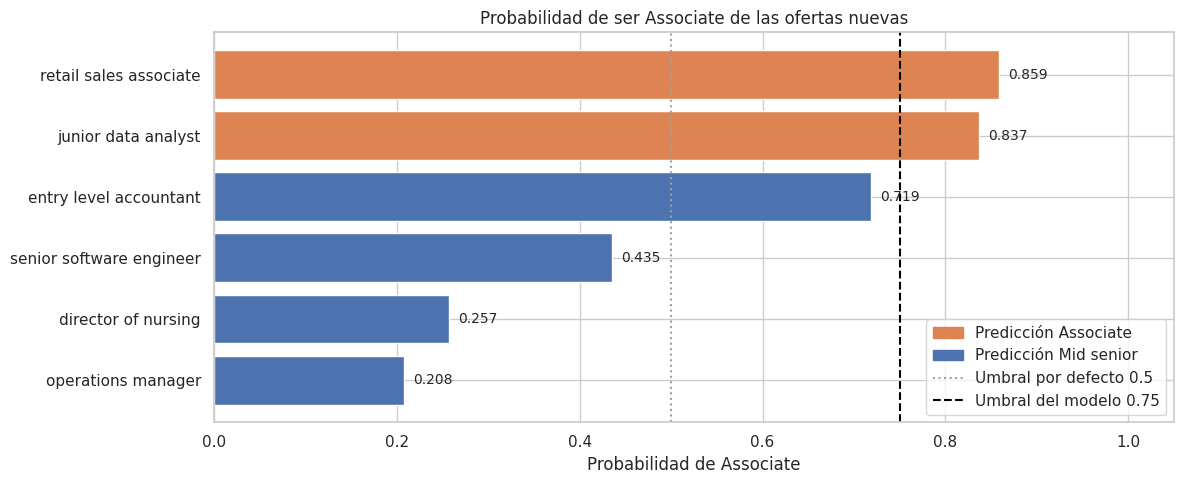

In [163]:
pd_nuevas = pred_nuevas.select("job_title", "prob_associate", "prediccion").toPandas().sort_values("prob_associate")

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(pd_nuevas["job_title"], pd_nuevas["prob_associate"],
        color=[COLORES_NIVEL[p] for p in pd_nuevas["prediccion"]])
for i, p in enumerate(pd_nuevas["prob_associate"]):
    ax.text(p + 0.01, i, f"{p:.3f}", va="center", fontsize=10)
ax.axvline(0.5, linestyle=":", color=COLOR_GRIS, label="Umbral por defecto 0.5")
ax.axvline(mejor_umbral, linestyle="--", color="black", label=f"Umbral del modelo {mejor_umbral}")
ax.set_xlim(0, 1.05)
ax.set_title("Probabilidad de ser Associate de las ofertas nuevas")
ax.set_xlabel("Probabilidad de Associate")
ax.legend(handles=[Patch(color=COLOR_ASSOC, label="Predicción Associate"),
                   Patch(color=COLOR_MID, label="Predicción Mid senior")] + ax.get_legend_handles_labels()[0],
          loc="lower right")
plt.tight_layout()
plt.show()

Las dos barras naranjas, retail sales associate con 0.860 y junior data analyst con 0.837, son las únicas que pasan la línea del umbral de 0.75. Entry level accountant, con 0.719, queda entre las dos líneas, con el umbral por defecto de 0.5 hubiera salido como Associate pero con el de 0.75 sale como Mid senior. Las otras tres quedan por debajo de 0.5, el ingeniero senior con 0.434, el director de enfermería con 0.254 y el gerente de operaciones con 0.208. La gráfica deja ver que el orden de las probabilidades tiene sentido, los puestos de entrada quedan arriba y los de dirección abajo, y que el único error es un caso cercano al umbral.

También reviso las predicciones en una muestra del conjunto de prueba comparadas con el valor real:

In [164]:
modelo_cargado.transform(test.sample(fraction=0.01, seed=7).limit(15)) \
    .withColumn("prob_associate", F.round(vector_to_array("probability")[1], 3)) \
    .select("job_title", "label", "prediction", "prob_associate") \
    .show(truncate=60)

+------------------------------------------------------------+-----+----------+--------------+
|                                                   job_title|label|prediction|prob_associate|
+------------------------------------------------------------+-----+----------+--------------+
|             assistant grocery manager - woolworths gundagai|    0|       0.0|         0.027|
|                                            field supervisor|    0|       0.0|         0.296|
|                                        general practitioner|    0|       0.0|         0.328|
|                       social worker - adults community team|    1|       1.0|         0.997|
|account executive, national sales - healthcare & senior l...|    0|       0.0|         0.074|
|               audio visual integration technician (level 2)|    0|       0.0|         0.609|
|                                    (can) department manager|    0|       0.0|         0.086|
|                  coordonnateur des comptes clien

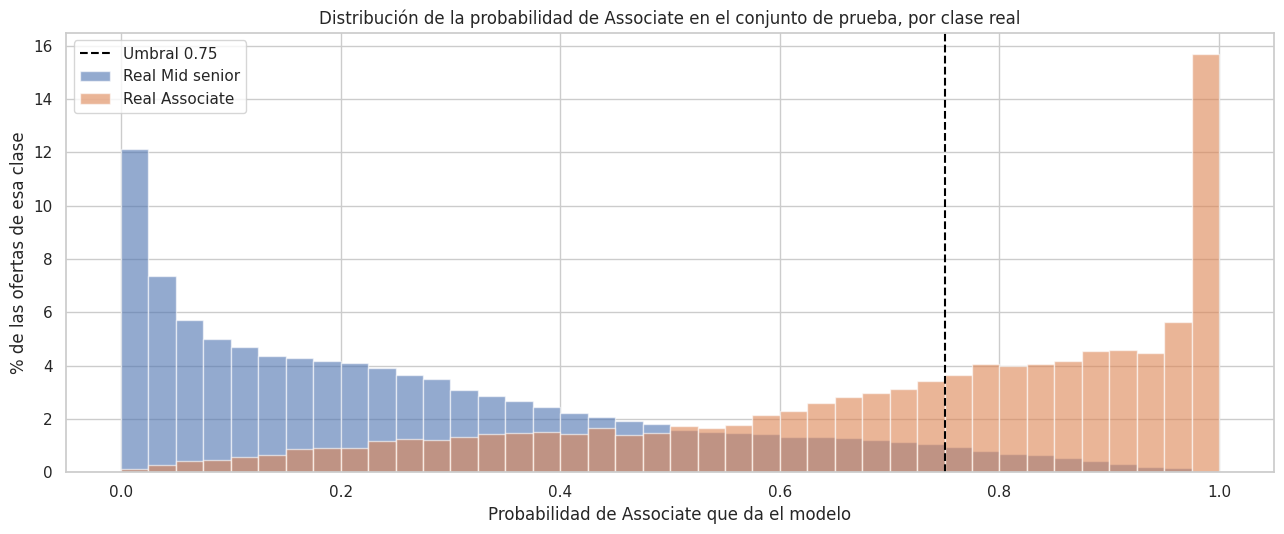

Associate: 11,462 de 20,876 ofertas arriba del umbral (54.9 %)
Mid senior: 8,258 de 173,009 ofertas arriba del umbral (4.8 %)


In [165]:
dist = pred_umbral.withColumn("p1", vector_to_array("probability")[1]) \
    .withColumn("bin", F.least(F.floor(F.col("p1") * 40), F.lit(39)) / 40) \
    .groupBy("label", "bin").count().toPandas()
dist["nivel"] = dist["label"].map({0: "Mid senior", 1: "Associate"})
dist["pct"] = dist["count"] / dist.groupby("label")["count"].transform("sum") * 100

fig, ax = plt.subplots(figsize=(13, 5.5))
for nivel in ["Mid senior", "Associate"]:
    d = dist[dist["nivel"] == nivel].sort_values("bin")
    ax.bar(d["bin"] + 1 / 80, d["pct"], width=1 / 40, alpha=0.6, color=COLORES_NIVEL[nivel],
           edgecolor="white", label=f"Real {nivel}")
ax.axvline(mejor_umbral, linestyle="--", color="black", label=f"Umbral {mejor_umbral}")
ax.set_title("Distribución de la probabilidad de Associate en el conjunto de prueba, por clase real")
ax.set_xlabel("Probabilidad de Associate que da el modelo")
ax.set_ylabel("% de las ofertas de esa clase")
ax.legend()
plt.tight_layout()
plt.show()

for nivel, lbl in [("Associate", 1), ("Mid senior", 0)]:
    d = dist[dist["label"] == lbl]
    arriba = d.loc[d["bin"] >= mejor_umbral, "count"].sum()
    print(f"{nivel}: {arriba:,} de {d['count'].sum():,} ofertas arriba del umbral ({arriba / d['count'].sum() * 100:.1f} %)")

La tabla anterior solo muestra 15 ejemplos, así que esta gráfica junta todo el conjunto de prueba. Cada barra es el porcentaje de las ofertas de esa clase real que cae en ese rango de probabilidad, así las dos clases se pueden comparar aunque Mid senior tenga ocho veces más ofertas. Las dos clases se separan bastante bien. Las Mid senior se concentran cerca de 0, con el pico más alto en el primer intervalo, y las Associate se concentran cerca de 1, con su pico en el último intervalo. Entre 0.4 y 0.7 las dos clases se enciman, y ahí es donde el modelo tiene más dudas. Lo que queda a la derecha de la línea punteada es lo que el modelo marca como Associate. Ahí cae el 54.9 % de las ofertas Associate reales, 11,464, y solo el 4.8 % de las Mid senior, 8,271, que coincide con la matriz de confusión del umbral 0.75. Las barras naranjas que quedan a la izquierda son las ofertas Associate que el modelo no detecta, y no están solo pegadas al umbral sino repartidas entre 0.1 y 0.75, y en la siguiente celda reviso un caso que explica parte de esos errores, ofertas con senior en el título que están etiquetadas como Associate.

In [166]:
senior_associate = df_modelo.filter((F.col("label") == 1) & F.col("job_title").contains("senior"))
print(f"Ofertas con senior en el título marcadas como Associate: {senior_associate.count():,}")
senior_associate.select("job_title").show(10, truncate=False)

Ofertas con senior en el título marcadas como Associate: 5,619
+------------------------------------------------------------+
|job_title                                                   |
+------------------------------------------------------------+
|analyst/ senior analyst (bangkok based, relocation provided)|
|client manager/senior accountant                            |
|senior account executive                                    |
|senior analyst | cfo advisory | canberra                    |
|senior analyst | external audit - asx listed | sydney       |
|senior associate, customer acquisition                      |
|senior auditor                                              |
|senior client executive                                     |
|senior commercial analyst                                   |
|senior facilities manager                                   |
+------------------------------------------------------------+
only showing top 10 rows


Hay 5,619 ofertas con senior en el título que vienen etiquetadas como Associate, por ejemplo senior auditor, senior analyst o senior facilities manager. Es probable que en varias de ellas la etiqueta job_level esté mal o que cada empresa use los niveles de forma distinta. Para el modelo son casos muy difíciles, porque la palabra senior empuja fuertemente hacia Mid senior, y explican parte de las 9,412 ofertas Associate que el modelo no detecta.

### Conclusiones del modelo

La regresión logística fue el mejor modelo. Comparada con la línea base, que no detecta ninguna oferta Associate, logra un AUC ROC de 0.89 y un AUC PR de 0.63, cuando un modelo al azar tendría un AUC PR de 0.11, que es la proporción de ofertas Associate. Naive Bayes quedó por debajo, con un AUC ROC de 0.82 y un AUC PR de 0.41, y la validación cruzada solo mejoró un poco al modelo inicial.

Con el umbral por defecto de 0.5 el modelo encontraba el 79 % de las ofertas Associate, pero solo el 35 % de las que marcaba como Associate lo eran, y su accuracy quedaba debajo de la línea base. Al ajustar el umbral a 0.75 con el conjunto de validación, el modelo final tiene una precision de 0.58, un recall de 0.55, un F1 de 0.56 y un accuracy de 0.91, que ya supera a la línea base. Elegir el umbral depende de para qué se use el modelo, si importa más no dejar pasar ofertas Associate conviene un umbral bajo, y si importa más no equivocarse al marcarlas conviene uno alto.

Las principales limitaciones que encontré son que algunos coeficientes altos corresponden a empresas en específico y no a características del puesto, que las habilidades no están unificadas y una misma habilidad aparece escrita de varias formas, y que la etiqueta job_level parece tener errores, porque hay ofertas con títulos senior marcadas como Associate. Para mejorar el modelo se podrían unificar las habilidades, quitar del título los nombres de empresas y probar con la descripción completa del puesto que no usé en este análisis.

# Parte 7: Exportación de datos para Tableau

Tableau no se puede conectar directo a Spark en Colab, entonces exporto los datos a archivos CSV en Drive y desde ahí los abro en Tableau Public. Las habilidades las exporto resumidas por nivel y país, porque una fila por habilidad serían más de 26 millones de filas y Tableau Public no acepta tantas en una sola fuente de datos. Solo incluyo las habilidades que aparecen en al menos 500 ofertas.

| Archivo | Contenido |
|---|---|
| ofertas.csv | Una fila por oferta con sus datos principales |
| habilidades.csv | Número de ofertas que piden cada habilidad por nivel y país |
| predicciones.csv | Predicción del modelo para cada oferta del conjunto de prueba |
| metricas.csv | Comparación de los modelos |
| coeficientes.csv | Palabras y habilidades con más peso en el modelo |

In [167]:
import shutil, glob

carpeta_tableau = os.path.join(carpeta_salida, "tableau")
os.makedirs(carpeta_tableau, exist_ok=True)

def exportar_csv(d, nombre):
    tmp = os.path.join(carpeta_tableau, nombre + "_tmp")
    d.coalesce(1).write.mode("overwrite").option("header", True).option("escape", '"').csv(tmp)
    parte = glob.glob(os.path.join(tmp, "part-*.csv"))[0]
    destino = os.path.join(carpeta_tableau, nombre + ".csv")
    shutil.move(parte, destino)
    shutil.rmtree(tmp)
    print(f"{nombre}.csv: {d.count():,} filas, {os.path.getsize(destino) / 1e6:.1f} MB")

df_limpio = spark.read.parquet(ruta_parquet)

# 1. Ofertas
ofertas = df_limpio.select("job_link", "job_title", "company", "job_location", "search_city",
                           "search_country", "search_position", "job_level", "job_type",
                           "first_seen", "day_of_week", "num_skills", "title_words")
exportar_csv(ofertas, "ofertas")

# 2. Habilidades resumidas por nivel y país
skills_rows = df_limpio.select("job_level", "search_country", F.explode("skills_array").alias("skill"))
skills_frecuentes = skills_rows.groupBy("skill").count().filter(F.col("count") >= 500).select("skill")
habilidades = skills_rows.join(skills_frecuentes, on="skill") \
    .groupBy("skill", "job_level", "search_country").agg(F.count("*").alias("ofertas"))
exportar_csv(habilidades, "habilidades")

# 3. Predicciones del modelo sobre el conjunto de prueba
predicciones = modelo_cargado.transform(test) \
    .withColumn("prob_associate", F.round(vector_to_array("probability")[1], 4)) \
    .withColumn("real", F.when(F.col("label") == 1, "Associate").otherwise("Mid senior")) \
    .withColumn("predicho", F.when(F.col("prediction") == 1, "Associate").otherwise("Mid senior")) \
    .withColumn("resultado",
                F.when((F.col("label") == 1) & (F.col("prediction") == 1), "Verdadero positivo")
                 .when((F.col("label") == 0) & (F.col("prediction") == 1), "Falso positivo")
                 .when((F.col("label") == 1) & (F.col("prediction") == 0), "Falso negativo")
                 .otherwise("Verdadero negativo")) \
    .select("job_link", "real", "predicho", "resultado", "prob_associate")
exportar_csv(predicciones, "predicciones")

# 4. Métricas de los modelos
exportar_csv(df_resultados, "metricas")

# 5. Coeficientes con más peso hacia cada nivel
top_pos = df_coefs.orderBy(F.col("coeficiente").desc()).limit(25)
top_neg = df_coefs.orderBy(F.col("coeficiente").asc()).limit(25)
coeficientes = top_pos.union(top_neg) \
    .withColumn("indica", F.when(F.col("coeficiente") > 0, "Associate").otherwise("Mid senior"))
exportar_csv(coeficientes, "coeficientes")

print("\nArchivos en:", carpeta_tableau)

ofertas.csv: 1,294,343 filas, 335.3 MB
habilidades.csv: 33,761 filas, 1.4 MB
predicciones.csv: 193,885 filas, 29.0 MB
metricas.csv: 5 filas, 0.0 MB
coeficientes.csv: 50 filas, 0.0 MB

Archivos en: /content/drive/MyDrive/portafolio_bigdata/tableau


Al terminar cierro la sesión de Spark para liberar recursos.

In [168]:
spark.stop()

# Parte 8: Tableau

https://public.tableau.com/views/portafolio_bigdata/Anlisisdeofertas?:language=en-GB&:sid=&:redirect=auth&showOnboarding=true&:display_count=n&:origin=viz_share_link

Existen dos dashboards, Analisis de ofertas y Modelo.

| Hoja | Dashboard | Qué muestra |
|---|---|---|
| Indicadores | Análisis de ofertas | El número total de ofertas después de la limpieza y el porcentaje que son de nivel Associate |
| Ofertas por país | Análisis de ofertas | Cuántas ofertas hay en cada uno de los cuatro países, con el color más fuerte donde hay más ofertas. Al dar clic en un país se filtra el resto del dashboard |
| Associate por tipo de empleo | Análisis de ofertas | El porcentaje de ofertas Associate en los empleos presenciales, híbridos y remotos |
| Top empresas | Análisis de ofertas | Las empresas que publicaron más ofertas y cuántas son de cada nivel |
| Ofertas por fecha | Análisis de ofertas | Cuántas ofertas se publicaron cada día entre el 12 y el 17 de enero de 2024 |
| Habilidades más pedidas | Análisis de ofertas | Las 20 habilidades que aparecen en más ofertas y cuántas de esas ofertas son de cada nivel |
| Métricas | Modelo | La comparación de la línea base, la regresión logística inicial, la ajustada, la de umbral 0.75 y Naive Bayes |
| Matriz de confusión | Modelo | Cuántas ofertas del conjunto de prueba clasificó bien y mal el modelo final para cada nivel |
| Distribución de probabilidades | Modelo | Cómo se reparten las probabilidades que da el modelo a las ofertas de cada nivel real |

### Dashboard 1: Análisis de ofertas

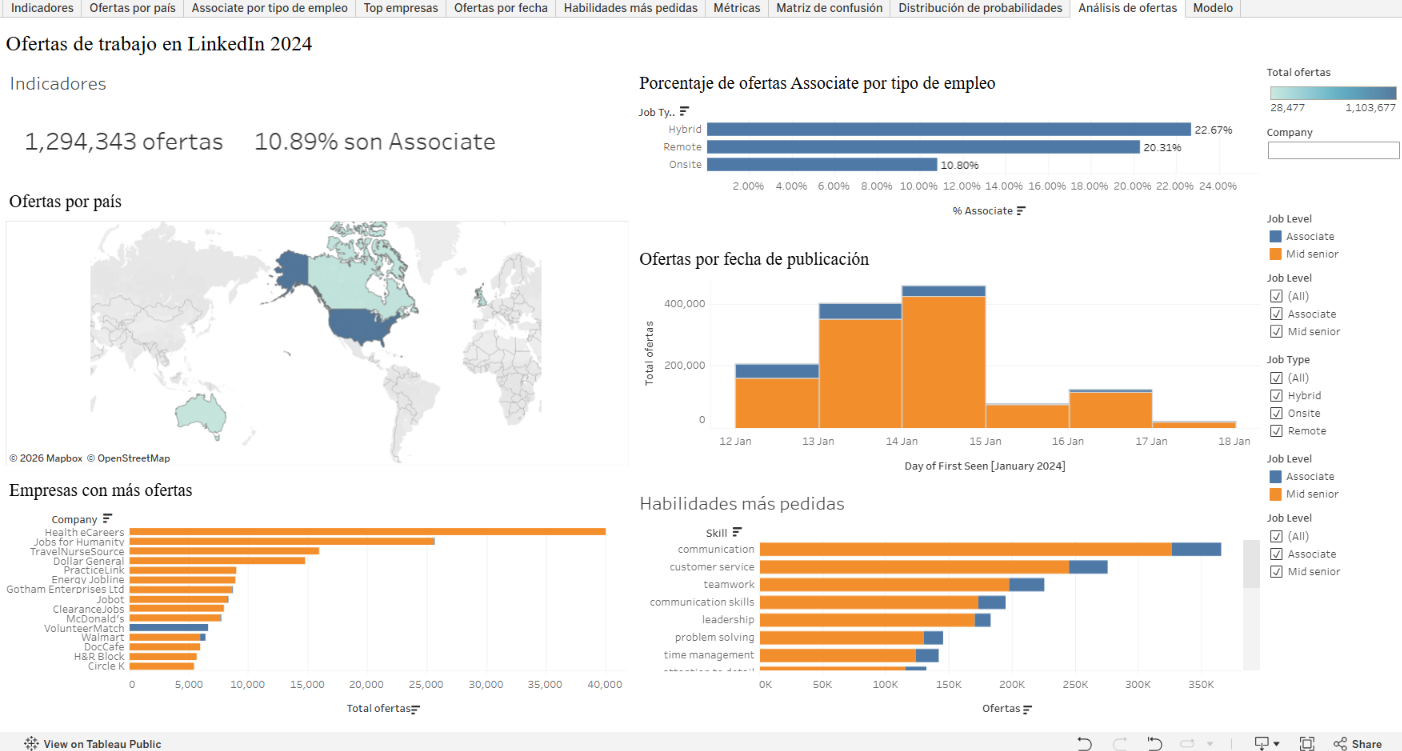

Los indicadores de arriba resumen el dataset limpio, 1,294,343 ofertas de las que el 10.89 % son Associate. El mapa deja ver que casi todas las ofertas son de Estados Unidos, y al dar clic en un país se filtran las demás gráficas. En la gráfica de tipo de empleo se repite lo que encontré en la estadística descriptiva, las ofertas híbridas y remotas tienen más del doble de Associate que las presenciales, 22.67 % y 20.31 % contra 10.80 %. En empresas destaca Health eCareers con unas 40 mil ofertas, casi todas Mid senior, y VolunteerMatch, que es de las pocas empresas del top con la mayoría de sus ofertas Associate. Eso coincide con que volunteer sea la palabra con el coeficiente más alto hacia Associate en el modelo. En habilidades, la parte azul de Associate es pequeña en todas las barras, porque las habilidades más comunes son casi las mismas en los dos niveles.

Este dashboard le sirve, por ejemplo, a alguien que busca su primer empleo o a un reclutador. Muestra que los puestos de entrada se concentran más en ofertas híbridas o remotas, qué empresas publican más ofertas de cada nivel y qué habilidades piden más. Con los filtros de nivel, tipo de empleo y empresa se puede ver lo mismo para un caso en específico.

### Dashboard 2: Modelo

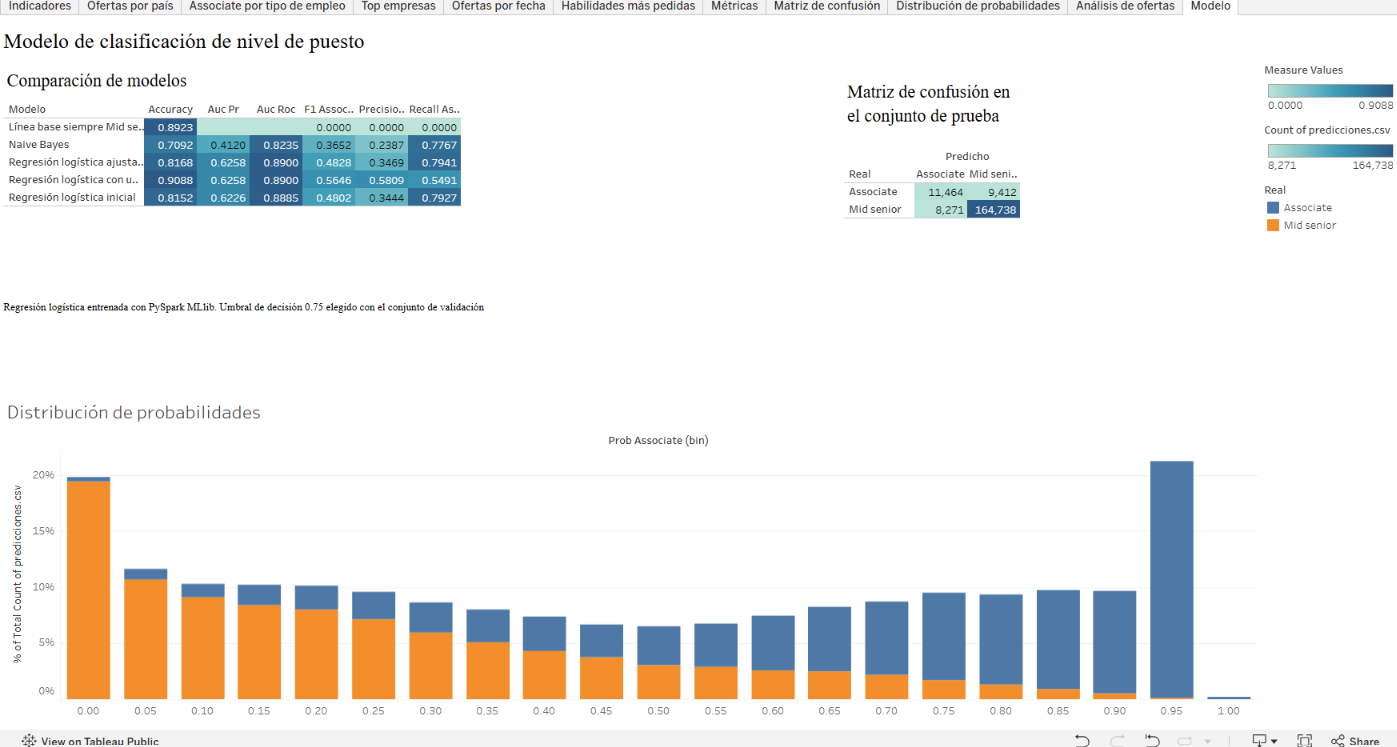

La tabla de comparación tiene los mismos valores que la sección 5.11. La regresión logística con umbral 0.75 tiene el mejor F1, 0.5646, y el mejor accuracy, 0.9088, y Naive Bayes queda por debajo en AUC ROC y sobre todo en AUC PR. La matriz de confusión muestra que el modelo final detecta 11,464 ofertas Associate y deja pasar 9,412, y que solo marca por error como Associate a 8,271 de las más de 173 mil ofertas Mid senior. En la distribución de probabilidades, las barras de la izquierda son casi todas naranjas, de ofertas Mid senior, y la última barra, de probabilidad entre 0.95 y 1, es casi toda azul. Es decir, cuando el modelo está muy seguro casi siempre acierta, y los errores se concentran en la zona media, donde las dos clases se mezclan.

Este dashboard sirve para decidir cómo usar el modelo. Si se usara para filtrar automáticamente ofertas de nivel de entrada, la distribución muestra que con un umbral alto los resultados son muy confiables pero se pierden ofertas, y con uno más bajo se encuentran más pero con más errores. La tabla y la matriz permiten ver ese intercambio con números.